# Classical AI: Types of AI and Intelligent Agents

> **Who is this for:** a beginner who has finished [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb) and knows high-school maths. It also works as revision if you are a university student getting ready for an AI exam or a job interview.
>
> **What you will learn**
> - A short history of AI: **symbolic AI** vs **machine learning**, and the two **AI winters**
> - The types of AI **by capability** (narrow, general, super) and **by functionality** (reactive, limited memory, theory of mind, self-aware), and which of them exist today
> - **Agents and environments**: percepts, actions, the agent function vs the agent program, **rationality**, **PEAS** descriptions and the 7 **environment properties**
> - The 5 classic **agent types** (simple reflex, model-based reflex, goal-based, utility-based, learning), each written in Python and tested in the same vacuum-cleaner world
> - How to **formulate a problem** for search: initial state, actions, transition model, goal test, path cost
> - **State-space graphs vs search trees**, with 4 worked formulations: the 8-puzzle, route finding, missionaries & cannibals and the water jug
>
> **Prerequisites:** [`00_AI_Fundamentals/00_start_here_what_is_ai.ipynb`](../00_start_here_what_is_ai.ipynb) and [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb) (functions, lists, dicts, classes).
>
> **Time needed:** about 2-3 hours.
>
> **Runs on:** CPU, no API key. Everything runs offline in a few seconds.
>
> **Optional track:** this notebook is part of the **university-level fundamentals track**. We recommend it for BS/MS AI students and for interview prep. You can skip it and go straight to Machine Learning, but the ideas here (agents, states, search) come back in Reinforcement Learning and LLM agents.

## Explained simply

AI means a computer program that chooses what to do in a smart way. One old and still very useful way to do that is to **think ahead**: imagine the possible moves and pick a sequence that reaches your goal, with no training data at all. In this notebook we sort out what kinds of AI really exist (and which ones are still science fiction), and we build small **agents**: programs that sense something, decide, and act. A **robot vacuum** is an agent: it senses dirt and bumps and decides where to move next. A **sat-nav** is another: it knows the roads and plans a route before you set off. Better agents remember what they have seen, plan ahead, weigh costs against rewards, and learn from experience.

**A tiny example.** A robot vacuum lives in a flat with 2 rooms, A and B. Both are dirty, and it starts in A. The simple rule "if dirty, suck; otherwise go to the other room" cleans the flat in 3 actions: Suck, Right, Suck. But if it keeps following that rule, it walks back and forth forever and wastes its battery. A robot that *remembers* that both rooms are already clean would stop. That one difference, memory, is what separates the first two agent types in Section 5.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Agent | something that senses, then acts | robot vacuum, a game character, an LLM chatbot that calls tools |
| Rational agent | does the best it can with what it knows | a sat-nav choosing the fastest route given today's traffic |
| Problem formulation | writing down the start, the possible moves, the goal and the cost before searching | planning a trip: home city, roads, destination, kilometres |

## Contents

1. A short history of AI: symbolic AI, machine learning and the AI winters
2. Types of AI by capability: narrow, general, super
3. Types of AI by functionality: reactive, limited memory, theory of mind, self-aware
4. Agents and environments: percepts, actions, agent function, rationality, PEAS, environment properties
5. The 5 agent types, coded and compared in a vacuum-cleaner world
6. Problem formulation, state-space graphs and search trees
7. Four example formulations: 8-puzzle, route finding, missionaries & cannibals, water jug
8. A map of the rest of this track
9. How this connects to modern AI
10. Recap, practice problems, further reading

### Setup

We only need the standard library, **NumPy**, **pandas**, **Matplotlib** and **NetworkX** (a library for drawing and analysing graphs). We fix the random seed so your numbers match the text.

In [1]:
import math                      # square roots, factorials
import random                    # random numbers (seeded below)
import itertools                 # products and permutations
from collections import deque    # a fast queue, used for flood-fill counting

import numpy as np               # numeric arrays
import pandas as pd              # tables
import matplotlib.pyplot as plt  # plots
import networkx as nx            # graphs: drawing and checking

SEED = 42                        # one seed for the whole notebook
random.seed(SEED)                # seed Python's random module
np.random.seed(SEED)             # seed NumPy's random module
pd.set_option("display.width", 140)          # wide tables print on one line
pd.set_option("display.max_colwidth", 60)    # but keep long text readable
plt.rcParams["figure.dpi"] = 100             # crisp, small figures
print("networkx", nx.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

networkx 3.7 | numpy 2.4.6 | pandas 2.3.3


## 1. A short history of AI

> 💬 **In plain English:** people have built AI in two ways, by writing rules by hand or by learning from data, and both went through boom and bust.

**Intuition.** There are two big ways to make a computer act intelligently:

1. **Write the knowledge down yourself.** You give the computer symbols (words like `Dirty`, `Room_A`) and rules (`if Dirty then Suck`), and it reasons or searches with them. This is **symbolic AI**, also called **classical AI** or **GOFAI** ("Good Old-Fashioned AI", a name coined by the philosopher John Haugeland in 1985).
2. **Let the computer find the rules from examples.** You give it data and it fits a model. This is **machine learning (ML)**.

*Everyday analogy:* teaching someone to cook by handing them a recipe book (symbolic) vs letting them taste hundreds of dishes and work out what makes a dish good (ML).

This whole track is about the first way: **search, logic and planning**. These methods reach goals by *thinking ahead* about actions, and they need no training data.

### Key dates

| Year | Event | Which camp |
|---|---|---|
| 1943 | McCulloch & Pitts describe a mathematical model of a neuron | early neural nets |
| 1950 | Alan Turing's paper *Computing Machinery and Intelligence* proposes the "imitation game" (the **Turing test**) | foundations |
| 1956 | Dartmouth workshop. The name "artificial intelligence" comes from the 1955 proposal by McCarthy, Minsky, Rochester and Shannon | birth of the field |
| 1956-59 | Newell & Simon's *Logic Theorist* and *General Problem Solver* prove theorems and solve puzzles by search | symbolic |
| 1958 | Rosenblatt's **perceptron**, a neuron that learns its weights | learning |
| 1966 | ELIZA, a rule-based chatbot (Weizenbaum) | symbolic |
| 1968 | **A\*** search published (Hart, Nilsson, Raphael), built for the Shakey robot | symbolic (search) |
| 1969 | Minsky & Papert's book *Perceptrons* shows the limits of single-layer perceptrons | |
| 1973 | UK **Lighthill report** criticises AI; funding is cut. **First AI winter** (about 1974-1980) | |
| 1980s | **Expert systems** boom (MYCIN for medicine, XCON/R1 for configuring DEC computers) | symbolic |
| 1986 | Rumelhart, Hinton & Williams popularise **backpropagation** for multi-layer networks | learning |
| 1987 | The Lisp-machine market collapses; expert systems prove costly to maintain. **Second AI winter** (about 1987-1993) | |
| 1997 | IBM **Deep Blue** beats world chess champion Garry Kasparov using search plus a hand-written evaluation function | symbolic (search) |
| 2012 | **AlexNet** wins the ImageNet image-recognition contest by a wide margin: the deep-learning era begins | learning |
| 2016 | DeepMind's **AlphaGo** beats Lee Sedol at Go, combining tree search with neural networks | hybrid |
| 2017 | The **Transformer** architecture ("Attention Is All You Need") | learning |
| 2022 | ChatGPT is released and makes large language models (LLMs) mainstream | learning |
| 2024 | Nobel Prizes: Physics to Hopfield and Hinton (neural networks); Chemistry shared by Hassabis and Jumper (AlphaFold) with Baker | learning |
| 2024-2026 | "Reasoning" LLMs that think step by step, and LLM **agents** that plan and call tools | hybrid |

An **AI winter** is a period when hopes were too high, results disappointed, and money and interest dried up.

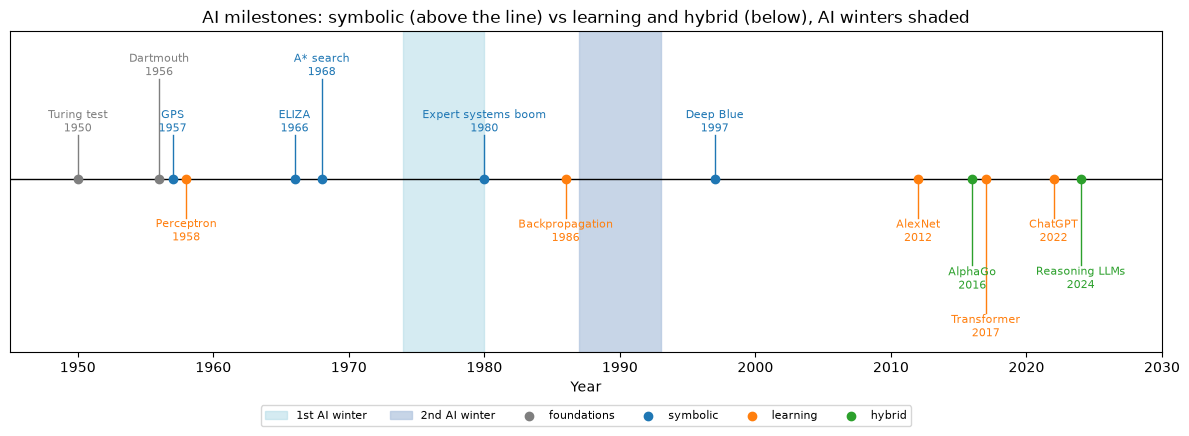

In [2]:
# A timeline plot: symbolic milestones above the line, learning/hybrid milestones below, winters shaded.
events = [  # (year, label, camp, height of the label; + above the axis, - below)
    (1950, "Turing test", "foundations", 1.0), (1956, "Dartmouth", "foundations", 2.3),
    (1957, "GPS", "symbolic", 1.0), (1958, "Perceptron", "learning", -0.9),
    (1966, "ELIZA", "symbolic", 1.0), (1968, "A* search", "symbolic", 2.3),
    (1980, "Expert systems boom", "symbolic", 1.0), (1986, "Backpropagation", "learning", -0.9),
    (1997, "Deep Blue", "symbolic", 1.0), (2012, "AlexNet", "learning", -0.9),
    (2016, "AlphaGo", "hybrid", -2.0), (2017, "Transformer", "learning", -3.1),
    (2022, "ChatGPT", "learning", -0.9), (2024, "Reasoning LLMs", "hybrid", -2.0),
]
colors = {"foundations": "tab:gray", "symbolic": "tab:blue", "learning": "tab:orange", "hybrid": "tab:green"}
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.axvspan(1974, 1980, color="lightblue", alpha=0.5, label="1st AI winter")      # shade winter 1
ax.axvspan(1987, 1993, color="lightsteelblue", alpha=0.7, label="2nd AI winter")  # shade winter 2
ax.axhline(0, color="black", lw=1)                                                # the time axis
for year, label, camp, h in events:
    ax.plot([year, year], [0, h], color=colors[camp], lw=1)                       # stem
    ax.scatter(year, 0, color=colors[camp], zorder=3)                             # dot on the axis
    ax.text(year, h, f"{label}\n{year}", ha="center", va="bottom" if h > 0 else "top",
            fontsize=8, color=colors[camp])
for camp, col in colors.items():                       # legend entries for the camps
    ax.scatter([], [], color=col, label=camp)
ax.set_ylim(-4.0, 3.4); ax.set_yticks([]); ax.set_xlim(1945, 2030)
ax.set_xlabel("Year"); ax.set_title("AI milestones: symbolic (above the line) vs learning and hybrid (below), AI winters shaded")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), fontsize=8, ncol=6)
plt.tight_layout(); plt.show()

**What just happened?** The plot puts the table on one axis. Until about 1990 most progress came from the symbolic camp (blue, above the line). Since 2012 most headlines come from learning (orange, below). The most famous recent systems (AlphaGo, reasoning LLMs, LLM agents) are **hybrids**: they combine learned models with search or planning, which is why the classical ideas in this track still matter.

### Symbolic AI vs machine learning

| | Symbolic (classical) AI | Machine learning |
|---|---|---|
| Where the knowledge comes from | people write it as rules, facts, models of actions | learned from data |
| Typical methods | search (BFS, A\*), logic and inference, planning, constraint solving | regression, trees, neural networks |
| Needs training data? | no | yes, often a lot |
| Strengths | exact, explainable, guarantees (e.g. "this path is the shortest"), works with zero data | handles messy perception (images, speech, text), adapts |
| Weaknesses | brittle when the world is messy; writing the knowledge is slow ("knowledge acquisition bottleneck") | needs data, can be hard to explain, few guarantees |
| Example | sat-nav route planner, chess engine search, airline crew scheduling | spam filter, face recognition, LLMs |

> ⚠️ **Common mistake:** "AI = machine learning." ML is one part of AI. A route planner using A\* is AI even though it learns nothing.

> 🎓 **Exam / interview tip:** be ready to name the two AI winters and their causes: (1) mid-1970s, after the Lighthill report and over-promised machine translation and perceptrons; (2) late 1980s-early 1990s, after the expert-system bubble and the Lisp-machine collapse.

## 2. Types of AI by capability

> 💬 **In plain English:** this sorts AI by how broad it is; everything that exists today is "narrow" AI.

This classification asks: **how broad is the system's intelligence?**

| Type | Also called | Definition | Exists today? (October 2026) | Examples |
|---|---|---|---|---|
| **Narrow AI** | **ANI**, **weak AI** | Performs a specific task or a bounded set of tasks. Outside its domain it fails or needs to be rebuilt or retrained. | **Yes: every AI system that exists is narrow AI** in this sense | chess engines, sat-nav, spam filters, face unlock, recommender systems, today's LLM chatbots |
| **General AI** | **AGI**, strong AI (loosely) | A *hypothetical* system that can learn and perform essentially any intellectual task a human can, at human level, and transfer what it knows to new domains | **No.** There is no agreed definition and no system that the research community broadly accepts as AGI | none (a research goal and a subject of debate) |
| **Super AI** | **ASI**, superintelligence | A *hypothetical* system that greatly exceeds the best humans in almost every domain | **No.** It is speculative | none (discussed in safety and philosophy, e.g. Bostrom's 2014 book *Superintelligence*) |

**Where do LLMs fit?** Modern LLMs are much more *general-purpose* than older systems: one model can write code, translate, summarise and answer questions. Even so, they still make basic reasoning errors, cannot reliably learn new skills after deployment, and need humans and tools around them. Some companies and researchers claim AGI is close; others think it is far away or badly defined. A careful, accurate statement is: **AGI has not been demonstrated, and ASI does not exist.**

> ⚠️ **Common mistake:** saying "ChatGPT is AGI" or "AGI already exists" in an exam. Unless your course says otherwise, the accepted answer is that all current AI is narrow (ANI).

> 🎓 **Exam / interview tip:** "weak AI vs strong AI" began as a *philosophy* distinction (John Searle, 1980). **Weak AI** means a machine that *acts as if* it is intelligent. **Strong AI** means a machine that *really has* a mind and understanding. Popular articles often use "weak = narrow" and "strong = general". If asked, mention both meanings.

## 3. Types of AI by functionality

> 💬 **In plain English:** this sorts AI by how much it remembers and understands; only the first two types exist.

This second, popular classification (often credited to Arend Hintze, 2016) asks: **how much memory and understanding of others does the system have?**

| Type | Definition | Exists today? | Example |
|---|---|---|---|
| **Reactive machines** | No memory of the past. The same input always gives the same output. They react only to the current situation. | Yes | IBM Deep Blue (looks at the current board only), a thermostat rule, the simple reflex agent in Section 5 |
| **Limited memory** | Use recent past data (a short history or what they learned from training data) to decide. | Yes, most modern AI | self-driving cars tracking nearby cars over the last few seconds, chatbots using the conversation so far, any trained ML model |
| **Theory of mind** | Would understand that other agents have beliefs, desires and intentions, and model them. | **No**, not in the full sense. It is a research area. LLMs pass some theory-of-mind *tests*, but whether they truly model minds is debated. | research prototypes |
| **Self-aware** | Would have consciousness and a sense of self. | **No.** Hypothetical | none |

> 🎓 **Exam / interview tip:** the textbook *Artificial Intelligence: A Modern Approach* (Russell & Norvig, "AIMA") does **not** use this 4-type list. AIMA classifies **agent programs** instead (simple reflex, model-based, goal-based, utility-based, learning), as we do in Section 5. GeeksforGeeks-style syllabi teach both. Know both, and know which ones are real.

Let's put a few real systems into both classifications as a table, and check that our labels follow the rules above.

In [3]:
# Each row: system, capability type, functionality type
systems = pd.DataFrame([
    ("Deep Blue (1997 chess)",            "Narrow (ANI)", "Reactive machine"),
    ("Sat-nav route planner (A*)",        "Narrow (ANI)", "Reactive machine"),
    ("Email spam filter",                 "Narrow (ANI)", "Limited memory"),
    ("Self-driving car",                  "Narrow (ANI)", "Limited memory"),
    ("LLM chat assistant (2026)",         "Narrow (ANI)", "Limited memory"),
    ("Hypothetical human-level AI",       "General (AGI) - hypothetical", "Theory of mind - hypothetical"),
    ("Hypothetical superintelligence",    "Super (ASI) - hypothetical",   "Self-aware - hypothetical"),
], columns=["System", "By capability", "By functionality"])
print(systems.to_string(index=False))

# Sanity check of the key fact: every system that exists today is narrow AI.
real = systems[~systems["System"].str.startswith("Hypothetical")]   # drop the made-up rows
assert (real["By capability"] == "Narrow (ANI)").all()               # all real systems are ANI
print("\nCheck passed: every real system in the table is narrow AI.")

                        System                By capability              By functionality
        Deep Blue (1997 chess)                 Narrow (ANI)              Reactive machine
    Sat-nav route planner (A*)                 Narrow (ANI)              Reactive machine
             Email spam filter                 Narrow (ANI)                Limited memory
              Self-driving car                 Narrow (ANI)                Limited memory
     LLM chat assistant (2026)                 Narrow (ANI)                Limited memory
   Hypothetical human-level AI General (AGI) - hypothetical Theory of mind - hypothetical
Hypothetical superintelligence   Super (ASI) - hypothetical     Self-aware - hypothetical

Check passed: every real system in the table is narrow AI.


**What just happened?** We built a small table and used an `assert` to check a fact: every *real* system is narrow AI. AGI, ASI, theory-of-mind and self-aware machines appear only as hypothetical rows.

A route planner is listed as a reactive machine: given the same map and the same start and goal, it always gives the same route, and it keeps no memory between queries. It still thinks ahead *within* one query by searching. That is the subject of this track.

## 4. Agents and environments

> 💬 **In plain English:** an agent is anything that senses its surroundings and acts on them, and we judge it by the results it produces.

### 4.1 Percepts, actions, agent function, agent program

**Intuition.** Think of a robot vacuum cleaner. It *senses* the floor (is this spot dirty? did I bump into something?) and it *acts* (move, suck). Anything that senses and acts like this is an **agent**.

- An **agent** is anything that **perceives** its **environment** through **sensors** and **acts** on it through **actuators**.
- A **percept** is what the agent senses at one moment. The **percept sequence** is the complete history of everything it has sensed so far.
- The **agent function** is the *mathematical* description of behaviour: a mapping from every possible percept sequence to an action, $f: P^* \rightarrow A$.
- The **agent program** is the *concrete code* that implements the agent function and runs on some physical **architecture** (computer + sensors + actuators). In AIMA's words: **agent = architecture + program**.

```
            percepts (sensors)
   +--------------------------------+
   |                                v
+-------------+               +-----------+
| ENVIRONMENT |               |   AGENT   |   agent program:
|  (world)    |               |  program  |   percept -> action
+-------------+               +-----------+
   ^                                |
   +--------------------------------+
            actions (actuators)
```

**Worked example by hand: the 2-square vacuum world** (AIMA chapter 2). There are two squares, `A` (left) and `B` (right). Each is `Clean` or `Dirty`. The agent's percept is `(location, status)`. Its actions are `Left`, `Right`, `Suck`, `NoOp` (do nothing).

Part of the **agent function** written as a table:

| Percept sequence | Action |
|---|---|
| `[(A, Clean)]` | `Right` |
| `[(A, Dirty)]` | `Suck` |
| `[(B, Clean)]` | `Left` |
| `[(B, Dirty)]` | `Suck` |
| `[(A, Clean), (A, Clean)]` | `Right` |
| `[(A, Clean), (A, Dirty)]` | `Suck` |
| ... | ... |

The table goes on forever, because percept sequences can be any length. A short **agent program** gives the same behaviour in 4 lines. Let's code both and check that they agree.

In [4]:
LOCATIONS = ["A", "B"]
STATUSES = ["Clean", "Dirty"]
ALL_PERCEPTS = [(loc, st) for loc in LOCATIONS for st in STATUSES]   # 4 possible percepts

def reflex_vacuum_agent(percept):
    # The agent PROGRAM: only looks at the current percept.
    location, status = percept          # unpack the percept
    if status == "Dirty":               # dirt here -> clean it
        return "Suck"
    elif location == "A":               # clean and in A -> go to B
        return "Right"
    else:                               # clean and in B -> go to A
        return "Left"

def build_agent_function_table(program, max_len):
    # Tabulate the agent FUNCTION: every percept sequence up to max_len -> action.
    table = {}
    for n in range(1, max_len + 1):                          # sequence lengths 1..max_len
        for seq in itertools.product(ALL_PERCEPTS, repeat=n):  # all sequences of that length
            table[seq] = program(seq[-1])                     # this program uses only the last percept
    return table

def make_table_driven_agent(table):
    # AIMA's TABLE-DRIVEN-AGENT: remembers all percepts and looks the whole sequence up.
    percepts = []                         # the percept sequence so far
    def program(percept):
        percepts.append(percept)          # add the new percept
        return table[tuple(percepts)]     # look up the action for the whole sequence
    return program

table = build_agent_function_table(reflex_vacuum_agent, max_len=4)
print("table entries for sequences up to length 4:", len(table))

# Check: the table-driven agent and the 4-line program behave identically on random runs.
rng = random.Random(SEED)
for trial in range(200):
    table_agent = make_table_driven_agent(table)        # fresh agent, empty memory
    for step in range(4):
        p = rng.choice(ALL_PERCEPTS)                     # a random percept
        assert table_agent(p) == reflex_vacuum_agent(p)  # same action from both programs
print("Check passed: two different programs, one agent function.")

# How fast does the table grow?  sum_{t=1..T} |P|^t entries for a lifetime of T percepts.
sizes = pd.DataFrame({"lifetime T": [1, 2, 5, 10, 20]})
sizes["table entries (|P| = 4)"] = [sum(4 ** t for t in range(1, T + 1)) for T in sizes["lifetime T"]]
print(sizes.to_string(index=False))

table entries for sequences up to length 4: 340
Check passed: two different programs, one agent function.
 lifetime T  table entries (|P| = 4)
          1                        4
          2                       20
          5                     1364
         10                  1398100
         20            1466015503700


**What just happened?**
- The **table** (the agent function written out) for sequences of length 1 to 4 already has 4 + 16 + 64 + 256 = 340 entries.
- The **4-line program** gives exactly the same actions. The `assert` checked 200 random runs. One agent function can be implemented by many programs, and a good program is far smaller than the table.
- The table size is $\sum_{t=1}^{T} |P|^t$. With only 4 possible percepts and a lifetime of 20 steps, that is about $1.5 \times 10^{12}$ entries. A taxi camera produces far more than 4 possible percepts per frame, so table-driven agents are hopeless. **The key challenge of AI is to write small programs that produce rational behaviour.**

**Complexity:** a table-driven agent needs $O(|P|^T)$ memory. The reflex program needs $O(1)$ memory and $O(1)$ time per step.

### 4.2 Rationality

**Intuition.** A rational agent "does the right thing". But *right* according to what? We need a score.

- A **performance measure** scores the sequence of environment states the agent caused. It is chosen by the designer, and it should measure **what you want in the world**, not how you think the agent should behave.
- **Definition (AIMA):** *For each possible percept sequence, a **rational agent** selects an action that is expected to maximise its performance measure, given the evidence provided by the percept sequence and whatever built-in knowledge the agent has.*
- What is rational at any time depends on 4 things: the **performance measure**, the agent's **prior knowledge** of the environment, the **actions** it can perform, and its **percept sequence** to date.
- **Rational is not omniscient.** An omniscient agent knows the actual outcome of its actions. A rational agent maximises the *expected* outcome given what it knows. If you cross the road after looking both ways and a piece of a passing plane falls on you, your decision was still rational.
- **Autonomy:** an agent is **autonomous** to the extent that it relies on its own percepts and learning instead of only its designer's prior knowledge.

Let's test whether the reflex vacuum agent is rational under two different performance measures:

- **Measure 1:** +1 for each clean square at each time step (AIMA's measure).
- **Measure 2:** Measure 1, minus 1 point for every `Left`/`Right` move (moving wears the motor and uses electricity).

In [5]:
def run_two_square(agent_program, start_loc, dirt, steps=10, move_penalty=0):
    # Simulate the 2-square world and return the performance score.
    dirt = dict(dirt)                       # copy {"A": bool, "B": bool}
    loc, score = start_loc, 0
    for t in range(steps):
        percept = (loc, "Dirty" if dirt[loc] else "Clean")
        action = agent_program(percept)
        if action == "Suck":
            dirt[loc] = False               # sucking always works here
        elif action == "Right":
            loc = "B"; score -= move_penalty
        elif action == "Left":
            loc = "A"; score -= move_penalty
        score += sum(not d for d in dirt.values())   # +1 per clean square this step
    return score

def make_model_based_two_square():
    # Remembers what it has seen, and stops moving once both squares are known to be clean.
    known = {"A": None, "B": None}          # None = never seen
    def program(percept):
        loc, status = percept
        known[loc] = status                 # update the internal model with the percept
        if status == "Dirty":
            known[loc] = "Clean"            # model of the action: after Suck, it will be clean
            return "Suck"
        other = "B" if loc == "A" else "A"
        if known[other] == "Clean":         # both clean (and dirt never comes back here)
            return "NoOp"
        return "Right" if loc == "A" else "Left"
    return program

configs = [(loc, {"A": da, "B": db}) for loc in "AB" for da in (False, True) for db in (False, True)]
rows = []
for penalty, name in [(0, "Measure 1 (clean squares)"), (1, "Measure 2 (minus 1 per move)")]:
    reflex = np.mean([run_two_square(reflex_vacuum_agent, l, d, move_penalty=penalty) for l, d in configs])
    model = np.mean([run_two_square(make_model_based_two_square(), l, d, move_penalty=penalty) for l, d in configs])
    rows.append((name, reflex, model))
rationality = pd.DataFrame(rows, columns=["performance measure", "simple reflex (avg)", "model-based (avg)"])
print("Average score over all 8 starting configurations, 10 steps each:")
print(rationality.to_string(index=False))
assert rationality.iloc[0, 1] == rationality.iloc[0, 2]   # equal under measure 1
assert rationality.iloc[1, 2] > rationality.iloc[1, 1]    # model-based wins under measure 2

Average score over all 8 starting configurations, 10 steps each:
         performance measure  simple reflex (avg)  model-based (avg)
   Measure 1 (clean squares)                19.25              19.25
Measure 2 (minus 1 per move)                10.25              18.25


**What just happened?** We averaged over all 8 starting situations (2 start squares × 4 dirt patterns).
- Under **Measure 1** both agents score the same (19.25). The simple reflex agent is rational for this measure: no agent can clean faster, and moving is free.
- Under **Measure 2** the reflex agent keeps walking back and forth forever and loses points. The model-based agent remembers that both squares are clean and stops, so it scores much higher.

So **rationality depends on the performance measure**. The same behaviour can be rational under one measure and irrational under another.

> ⚠️ **Common mistake:** rewarding the agent for *behaviour* instead of *results*. If you give +1 for every `Suck`, an agent can score forever by sucking a clean floor. Reward clean floors, not sucking.

### 4.3 PEAS: describing the task environment

Before designing an agent, write down its **task environment** as **PEAS**: **P**erformance measure, **E**nvironment, **A**ctuators, **S**ensors.

| Agent | Performance measure | Environment | Actuators | Sensors |
|---|---|---|---|---|
| **Automated taxi** | safe, fast, legal, comfortable trip; maximise profit; minimise impact on other road users | roads, other traffic, police, pedestrians, customers, weather | steering, accelerator, brake, signal, horn, display/speech | cameras, radar, lidar, speedometer, GPS, accelerometer, engine sensors, touchscreen/microphone |
| **Medical diagnosis system** | healthy patient, correct diagnosis, low cost, few unnecessary tests | patient, hospital, staff | display of questions, tests, diagnoses, treatments, referrals | touchscreen/keyboard entry of symptoms, findings, patient's answers, lab results |
| **Robot vacuum cleaner** (Section 5) | amount of dirt cleaned, minus energy used (moves), in the time available | rooms of a house, furniture, dirt, (people, pets) | wheels (move), suction (suck) | dirt sensor, bump sensor, (wheel encoders, camera on high-end models) |
| **Email spam filter** | few spam emails in the inbox (high recall) and almost no real emails lost (high precision) | user's mailbox, email senders, spammers who adapt | move to spam folder / keep in inbox, flag | incoming email text, headers, links, sender reputation, user's "not spam" clicks |

> 🎓 **Exam / interview tip:** PEAS questions are very common. Write the four headings and fill each with 3-5 concrete items. In the performance measure, mention trade-offs (speed vs safety, recall vs precision).

### 4.4 Properties of task environments

| Property | Question to ask | Easy case | Hard case |
|---|---|---|---|
| **Fully vs partially observable** | Do the sensors give the complete relevant state at each moment? | **fully**: chess board | **partially**: poker (hidden cards), taxi (cannot see round corners) |
| **Single vs multi-agent** | Are there other agents whose behaviour affects my score? | **single**: crossword | **multi**: chess (competitive), taxi (partly cooperative, partly competitive) |
| **Deterministic vs stochastic** | Is the next state fully determined by the current state and my action? | **deterministic**: 8-puzzle | **stochastic**: dice in backgammon, traffic. (*Nondeterministic* means several outcomes are possible but with no probabilities given.) |
| **Episodic vs sequential** | Does the current decision affect future decisions? | **episodic**: classifying one image, then the next, independently | **sequential**: chess, driving |
| **Static vs dynamic** | Can the world change while the agent is thinking? | **static**: crossword | **dynamic**: taxi. **Semi-dynamic**: the world does not change but the score does, e.g. chess with a clock |
| **Discrete vs continuous** | Are states, time, percepts and actions countable or real-valued? | **discrete**: chess | **continuous**: taxi speed and steering angle |
| **Known vs unknown** | Does the *agent* (or its designer) know the rules of the world, i.e. the outcome or outcome probabilities of each action? | **known**: games with given rules | **unknown**: a new video game where you must learn what the buttons do |

**Known vs unknown is not the same as fully vs partially observable.** Solitaire card games are *known* (you know the rules) but *partially observable* (cards are face down). A new video game can be *fully observable* (you see the whole screen) but *unknown* (you do not know what the buttons do).

The table below classifies 10 task environments. The first 8 rows follow AIMA (4th edition, Figure 2.6); we added the vacuum world from Section 5 and the 8-puzzle.

                      Observable  Agents Deterministic?   Episodic?  Static?   Discrete?   Known?
Task                                                                                             
Crossword puzzle           Fully  Single  Deterministic  Sequential   Static    Discrete    Known
Chess with a clock         Fully   Multi  Deterministic  Sequential     Semi    Discrete    Known
Poker                  Partially   Multi     Stochastic  Sequential   Static    Discrete    Known
Backgammon                 Fully   Multi     Stochastic  Sequential   Static    Discrete    Known
Taxi driving           Partially   Multi     Stochastic  Sequential  Dynamic  Continuous  Depends
Medical diagnosis      Partially  Single     Stochastic  Sequential  Dynamic  Continuous  Depends
Image analysis             Fully  Single  Deterministic    Episodic     Semi  Continuous    Known
Part-picking robot     Partially  Single     Stochastic    Episodic  Dynamic  Continuous  Depends
Vacuum world (Sec. 5

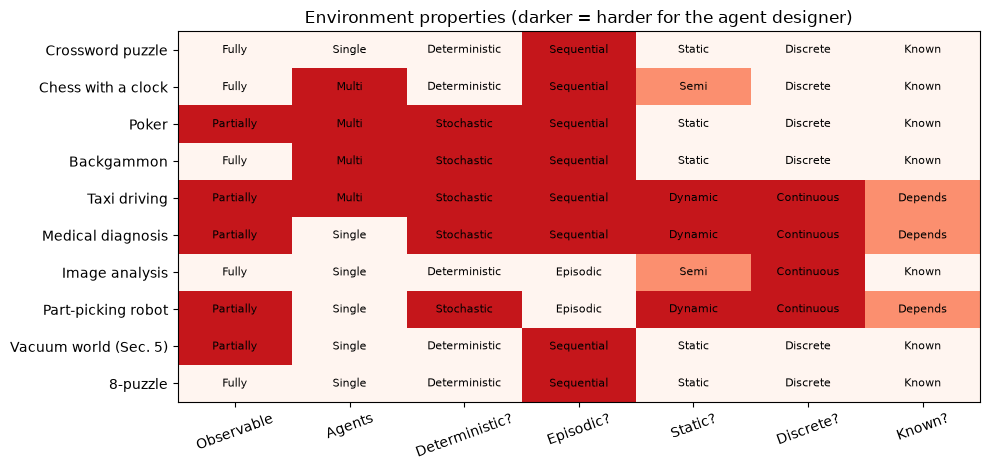

Hardness score per task (sum of the row):
Task
Crossword puzzle         1.0
8-puzzle                 1.0
Image analysis           1.5
Vacuum world (Sec. 5)    2.0
Chess with a clock       2.5
Backgammon               3.0
Poker                    4.0
Part-picking robot       4.5
Medical diagnosis        5.5
Taxi driving             6.5


In [6]:
env_rows = [
    # task,                 observable, agents,  deterministic,   episodic,     static,     discrete,     known
    ("Crossword puzzle",     "Fully",    "Single", "Deterministic", "Sequential", "Static",   "Discrete",   "Known"),
    ("Chess with a clock",   "Fully",    "Multi",  "Deterministic", "Sequential", "Semi",     "Discrete",   "Known"),
    ("Poker",                "Partially","Multi",  "Stochastic",    "Sequential", "Static",   "Discrete",   "Known"),
    ("Backgammon",           "Fully",    "Multi",  "Stochastic",    "Sequential", "Static",   "Discrete",   "Known"),
    ("Taxi driving",         "Partially","Multi",  "Stochastic",    "Sequential", "Dynamic",  "Continuous", "Depends"),
    ("Medical diagnosis",    "Partially","Single", "Stochastic",    "Sequential", "Dynamic",  "Continuous", "Depends"),
    ("Image analysis",       "Fully",    "Single", "Deterministic", "Episodic",   "Semi",     "Continuous", "Known"),
    ("Part-picking robot",   "Partially","Single", "Stochastic",    "Episodic",   "Dynamic",  "Continuous", "Depends"),
    ("Vacuum world (Sec. 5)","Partially","Single", "Deterministic", "Sequential", "Static",   "Discrete",   "Known"),
    ("8-puzzle",             "Fully",    "Single", "Deterministic", "Sequential", "Static",   "Discrete",   "Known"),
]
props = ["Observable", "Agents", "Deterministic?", "Episodic?", "Static?", "Discrete?", "Known?"]
env_df = pd.DataFrame(env_rows, columns=["Task"] + props).set_index("Task")
print(env_df.to_string())

# Turn the words into a difficulty score: 0 = easy value, 0.5 = semi/depends, 1 = hard value.
hard_values = {"Partially", "Multi", "Stochastic", "Sequential", "Dynamic", "Continuous", "Unknown"}
middle_values = {"Semi", "Depends"}
difficulty = env_df.apply(lambda col: col.map(lambda v: 1.0 if v in hard_values else (0.5 if v in middle_values else 0.0)))

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.imshow(difficulty.values, cmap="Reds", vmin=0, vmax=1.3, aspect="auto")
ax.set_xticks(range(len(props))); ax.set_xticklabels(props, rotation=20)
ax.set_yticks(range(len(env_df))); ax.set_yticklabels(env_df.index)
for i in range(len(env_df)):              # write the word in each cell
    for j in range(len(props)):
        ax.text(j, i, env_df.iloc[i, j], ha="center", va="center", fontsize=8)
ax.set_title("Environment properties (darker = harder for the agent designer)")
plt.tight_layout(); plt.show()
print("Hardness score per task (sum of the row):")
print(difficulty.sum(axis=1).sort_values().to_string())

**What just happened?** Each row is one task, each column one property. Dark cells are the hard values. The crossword and the 8-puzzle are the easiest kind of environment: fully observable, single-agent, deterministic, static, discrete and known. That is exactly the kind of environment that the **search algorithms** in notebooks 02 and 03 assume. Taxi driving is hard on every axis, which is why self-driving cars took decades.

**"Depends"** in the *Known?* column means the answer depends on how the agent is built, not on the task. A taxi with a detailed physics model of its own car and of the traffic rules works in a known environment. A taxi dropped into a city whose traffic rules it was never told works in an unknown one.

Our vacuum world is **partially observable**: the robot's dirt sensor sees only its own square, so it cannot see dirt elsewhere. "Known" means our smarter agents are given the floor plan and know how their moves change their position.

> ⚠️ **Common mistakes**
> - "Stochastic" is about the *environment's* response to actions, not about whether the agent uses randomness.
> - Chess *with a clock* is **semi-dynamic**: the board does not change while you think, but your time runs out.
> - "Known/unknown" describes the agent's knowledge of the rules, not what it can see.

## 5. The five agent types, coded and compared

> 💬 **In plain English:** we build five robot vacuums, from "no memory, no plan" to "learns from experience", and see which one cleans best.

AIMA describes 5 kinds of agent program, from simplest to most capable. We will implement all 5 for the **same** environment and the **same** percepts, and score them with the **same** performance measure, so the comparison is fair.

### Our vacuum world

- A 6 × 6 floor. 5 squares are furniture (black) and cannot be entered. That leaves 31 free squares.
- The robot starts in the top-left corner `(0, 0)`.
- At the start, each free square is dirty at random. The **kitchen** (the 6 shaded squares, bottom-right) is dirty with probability 0.8; every other square with probability 0.1. Dirt does not come back during an episode.
- **Percept** (the same for every agent): `(dirty_here, bumped)`, i.e. "is my square dirty?" and "did my last move hit a wall or furniture?". The robot has **no** GPS and **no** camera.
- **Actions:** `Up`, `Down`, `Left`, `Right`, `Suck`, `NoOp`.
- **Performance measure:** +10 for each dirty square cleaned, −1 for each move (`Up/Down/Left/Right`, even if it bumps), −1 for sucking a clean square, 0 for `NoOp`. The episode lasts **T = 40** time steps.

free squares: 31 | expected dirty squares per episode: 7.3


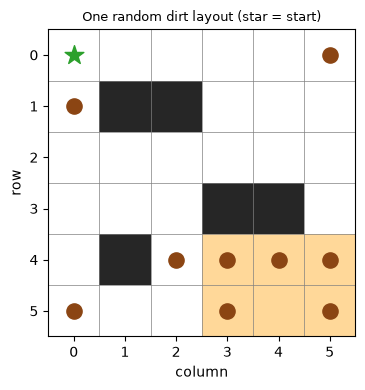

In [7]:
ROWS, COLS = 6, 6                                      # grid size
OBSTACLES = {(1, 1), (1, 2), (3, 3), (3, 4), (4, 1)}  # furniture squares
KITCHEN = {(r, c) for r in (4, 5) for c in (3, 4, 5)}  # the dirty-prone area
START = (0, 0)                                         # robot's start square
T_STEPS = 40                                           # episode length
MOVES = {"Up": (-1, 0), "Down": (1, 0), "Left": (0, -1), "Right": (0, 1)}
FREE = [(r, c) for r in range(ROWS) for c in range(COLS) if (r, c) not in OBSTACLES]
P_DIRT = {cell: (0.8 if cell in KITCHEN else 0.1) for cell in FREE}  # true dirt probabilities
print("free squares:", len(FREE), "| expected dirty squares per episode:", round(sum(P_DIRT.values()), 1))

def make_dirt(rng):
    # One random starting layout of dirt.
    return {cell for cell in FREE if rng.random() < P_DIRT[cell]}

def try_move(pos, action):
    # Physics of the world: returns (new_position, bumped?).
    dr, dc = MOVES[action]
    new = (pos[0] + dr, pos[1] + dc)
    if 0 <= new[0] < ROWS and 0 <= new[1] < COLS and new not in OBSTACLES:
        return new, False           # moved successfully
    return pos, True                # hit a wall/furniture: stay put, bump sensor fires

def run_episode(agent, dirt, steps=T_STEPS):
    # Run one episode; return the score and the list of positions visited (for plotting).
    pos, dirt, score, bumped = START, set(dirt), 0, False
    trail = [pos]
    for t in range(steps):
        percept = (pos in dirt, bumped)       # what the robot senses
        action = agent(percept)               # the agent program chooses
        bumped = False
        if action == "Suck":
            if pos in dirt:
                dirt.discard(pos); score += 10    # cleaned a dirty square
            else:
                score -= 1                        # wasted suck
        elif action in MOVES:
            score -= 1                            # every move costs energy
            pos, bumped = try_move(pos, action)
        trail.append(pos)
    return score, trail

def draw_world(ax, dirt=(), trail=None, title=""):
    # Picture of the floor: furniture black, kitchen orange, dirt brown dots, trail blue line.
    img = np.ones((ROWS, COLS, 3))
    for (r, c) in KITCHEN: img[r, c] = (1.0, 0.85, 0.6)
    for (r, c) in OBSTACLES: img[r, c] = (0.15, 0.15, 0.15)
    ax.imshow(img)
    for (r, c) in dirt: ax.scatter(c, r, s=120, color="saddlebrown", marker="o")
    if trail:
        ys, xs = zip(*trail)
        ax.plot(xs, ys, color="tab:blue", lw=2, alpha=0.7)
    ax.scatter(START[1], START[0], s=200, marker="*", color="tab:green", zorder=3)
    ax.set_xticks(range(COLS)); ax.set_yticks(range(ROWS)); ax.set_title(title, fontsize=9)
    ax.set_xticks(np.arange(-.5, COLS), minor=True); ax.set_yticks(np.arange(-.5, ROWS), minor=True)
    ax.grid(which="minor", color="gray", lw=0.5); ax.tick_params(which="minor", length=0)

example_dirt = make_dirt(random.Random(3))
fig, ax = plt.subplots(figsize=(4, 4))
draw_world(ax, example_dirt, title="One random dirt layout (star = start)")
ax.set_xlabel("column"); ax.set_ylabel("row")
plt.tight_layout(); plt.show()

**What just happened?** We wrote the environment: the floor, the dirt generator, the physics of moving (`try_move`) and the scoring loop (`run_episode`). Notice that the agent only ever receives `(dirty_here, bumped)`. Everything else it "knows" must come from its own program.

Some helper code for the smarter agents. Agents 2-5 are given the **floor plan** (the map is *known*) and the start square. They can work out where they are by **dead reckoning**: "I was at (2, 3) and moved Right without bumping, so now I am at (2, 4)." This is the "how my actions change the world" part of a model.

In [8]:
def neighbours(cell):
    # Free squares next to `cell`, as (action, square) pairs.
    out = []
    for action, (dr, dc) in MOVES.items():
        n = (cell[0] + dr, cell[1] + dc)
        if 0 <= n[0] < ROWS and 0 <= n[1] < COLS and n not in OBSTACLES:
            out.append((action, n))
    return out

def shortest_paths_from(src):
    # Breadth-first flood fill: distance and parent pointer for every reachable square.
    # (Notebook 02 explains breadth-first search in detail.)
    dist, parent = {src: 0}, {src: None}
    queue = deque([src])
    while queue:
        u = queue.popleft()
        for action, v in neighbours(u):
            if v not in dist:
                dist[v] = dist[u] + 1
                parent[v] = (u, action)
                queue.append(v)
    return dist, parent

def path_to(parent, target):
    # Follow parent pointers back from target; return (actions, squares) in forward order.
    actions, squares = [], []
    while parent[target] is not None:
        prev, action = parent[target]
        actions.append(action); squares.append(target)
        target = prev
    return actions[::-1], squares[::-1]

### 5.1 Simple reflex agent

**Definition.** A **simple reflex agent** chooses its action from the **current percept only**, using **condition-action rules** ("if dirty then suck"). It has no memory.

```
percept --> [ what is the world like now? ] --> [ condition-action rules ] --> action
```

Our robot only senses its own square and has no memory, so it cannot know where it has been. Its best option when the square is clean is to move in a **random** direction. Randomness helps a reflex agent escape loops: a deterministic "always go Right" rule would get stuck against the first wall forever.

In [9]:
class SimpleReflexAgent:
    def __init__(self, rng):
        self.rng = rng                                 # source of random moves

    def __call__(self, percept):
        dirty_here, bumped = percept                   # current percept only, no memory
        if dirty_here:                                 # rule 1: dirty -> Suck
            return "Suck"
        return self.rng.choice(list(MOVES))            # rule 2: otherwise wander randomly

### 5.2 Model-based reflex agent

**Definition.** A **model-based reflex agent** keeps an **internal state** that tracks the parts of the world it cannot see now. It updates the state using (1) a **transition model** (how its actions change the world) and (2) a **sensor model** (how the world shows up in percepts). It still picks actions with condition-action rules, but the rules can now look at the internal state.

```
percept --> [ update internal state using the model ] --> [ condition-action rules ] --> action
```

Our model-based robot remembers its position (dead reckoning) and **when it last visited each square**. Its rules are:
1. if dirty: `Suck`;
2. if every free square has been visited: `NoOp` (there is nothing left to clean);
3. otherwise move to a neighbouring square that was never visited, or, if there is none, to the neighbour visited *longest ago*.

It plans nothing. It only looks one square ahead.

In [10]:
class ModelBasedReflexAgent:
    def __init__(self):
        self.pos = START                   # internal state: believed position
        self.last_visit = {START: 0}       # internal state: square -> time of last visit
        self.t = 0                         # internal clock

    def __call__(self, percept):
        dirty_here, bumped = percept
        self.t += 1
        if dirty_here:                                     # rule 1
            return "Suck"
        if len(self.last_visit) == len(FREE):              # rule 2: whole floor visited
            return "NoOp"
        options = neighbours(self.pos)                     # uses the known floor plan
        # rule 3: never-visited squares count as time -1, so they are chosen first
        action, nxt = min(options, key=lambda an: self.last_visit.get(an[1], -1))
        self.pos = nxt                                     # dead reckoning (we never bump)
        self.last_visit[nxt] = self.t
        return action

### 5.3 Goal-based agent

**Definition.** A **goal-based agent** has an explicit **goal** (a description of desirable states) and **thinks ahead**: "what will happen if I do this sequence of actions, and will it reach my goal?". Choosing such a sequence is **search** or **planning**, the subject of the rest of this track.

```
percept --> [ state ] --> [ what will happen if I do action A? ] --> [ does it reach my GOAL? ] --> action
```

Our goal-based robot has the goal **"every free square visited (and so cleaned)"**. Whenever it has no plan, it searches for the shortest path to the **nearest unvisited square** and follows it.

In [11]:
class GoalBasedAgent:
    def __init__(self):
        self.pos = START
        self.visited = {START}
        self.plan = []                          # remaining actions of the current plan

    def __call__(self, percept):
        dirty_here, bumped = percept
        if dirty_here:
            return "Suck"
        if not self.plan:                                     # need a new plan
            unvisited = [c for c in FREE if c not in self.visited]
            if not unvisited:                                 # GOAL reached
                return "NoOp"
            dist, parent = shortest_paths_from(self.pos)      # look ahead (search)
            target = min(unvisited, key=lambda c: (dist[c], c))  # nearest unvisited square
            self.plan, _ = path_to(parent, target)
        action = self.plan.pop(0)                             # execute the next step
        self.pos, _ = try_move(self.pos, action)
        self.visited.add(self.pos)
        return action

### 5.4 Utility-based agent

**Definition.** A goal is a yes/no test: happy or unhappy. A **utility function** $U(s)$ gives a *number* that says **how** happy a state is. A **utility-based agent** chooses the action with the highest **expected utility** (probability-weighted average). This lets it make trade-offs: speed vs energy, likely reward vs certain cost, and how to choose between goals that cannot all be reached.

```
percept --> [ state ] --> [ what will happen if I do A? ] --> [ how happy will I be (utility)? ] --> action
```

Our utility-based robot knows the dirt probabilities (kitchen 0.8, elsewhere 0.1). For each unvisited square $c$ that it can still reach in time, it scores the plan "walk the shortest path to $c$":

$$\text{expected gain}(c) = \sum_{\text{unvisited squares } x \text{ on the path}} 10 \cdot P(\text{dirty}_x) \;-\; \text{number of moves}.$$

It picks the plan with the largest expected gain. If no plan has a positive gain, it does `NoOp`: walking to a square that is dirty only 10% of the time is worth 1 point on average, and the walk costs at least 1 point.

In [12]:
class UtilityBasedAgent:
    def __init__(self, p_dirt, steps=T_STEPS):
        self.p = p_dirt                         # beliefs: P(square is dirty)
        self.steps = steps
        self.pos, self.visited, self.plan, self.t = START, {START}, [], 0

    def expected_gain(self, squares, n_moves):
        # Expected points from cleaning the unvisited squares on the path, minus move costs.
        return sum(10 * self.p[x] for x in squares if x not in self.visited) - n_moves

    def __call__(self, percept):
        dirty_here, bumped = percept
        self.t += 1
        remaining = self.steps - self.t + 1      # time steps left including this one
        if dirty_here:
            return "Suck"
        if not self.plan:
            dist, parent = shortest_paths_from(self.pos)
            best_plan, best_gain = None, 0.0
            for c in FREE:
                if c in self.visited or dist[c] + 1 > remaining:  # must arrive AND have time to suck
                    continue
                actions, squares = path_to(parent, c)
                gain = self.expected_gain(squares, len(actions))
                if gain > best_gain + 1e-9:                       # strictly better plan
                    best_plan, best_gain = actions, gain
            if best_plan is None:                                 # nothing worth doing
                return "NoOp"
            self.plan = best_plan
        action = self.plan.pop(0)
        self.pos, _ = try_move(self.pos, action)
        self.visited.add(self.pos)
        return action

### Comparing the four agents

We run each agent on the **same 300 random dirt layouts** and average the scores. Same layouts means the comparison is fair: no agent gets luckier floors than another.

In [13]:
layouts = [make_dirt(random.Random(1000 + i)) for i in range(300)]   # 300 fixed test floors
reflex_rng = random.Random(SEED)                                     # randomness for the reflex agent
factories = {
    "1. Simple reflex": lambda: SimpleReflexAgent(reflex_rng),
    "2. Model-based reflex": ModelBasedReflexAgent,
    "3. Goal-based": GoalBasedAgent,
    "4. Utility-based": lambda: UtilityBasedAgent(P_DIRT),
}
results = {}
for name, make_agent in factories.items():
    scores = [run_episode(make_agent(), d)[0] for d in layouts]      # a fresh agent per episode
    results[name] = scores
summary = pd.DataFrame({
    "mean score": {k: np.mean(v) for k, v in results.items()},
    "std error": {k: np.std(v, ddof=1) / np.sqrt(len(v)) for k, v in results.items()},
    "worst": {k: np.min(v) for k, v in results.items()},
    "best": {k: np.max(v) for k, v in results.items()},
}).round(1)
print(summary.to_string())

means = summary["mean score"].values
assert means[0] < means[1] < means[2] < means[3], "expected the ordering simple < model < goal < utility"
print("\nCheck passed: each more sophisticated agent scores higher on average.")

                       mean score  std error  worst  best
1. Simple reflex            -24.5        0.9    -40    37
2. Model-based reflex        31.5        0.7     -4    70
3. Goal-based                38.6        1.0     -4    81
4. Utility-based             44.6        0.8     14    84

Check passed: each more sophisticated agent scores higher on average.


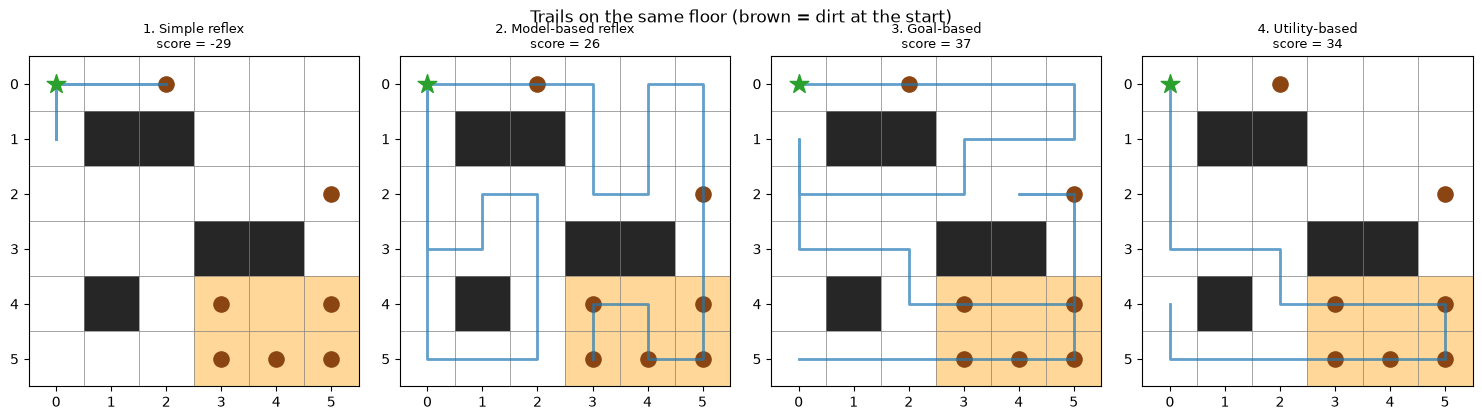

In [14]:
# Where does each agent actually go?  One layout, four trails.
demo_dirt = layouts[0]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, (name, make_agent) in zip(axes, factories.items()):
    score, trail = run_episode(make_agent(), demo_dirt)
    draw_world(ax, demo_dirt, trail, title=f"{name}\nscore = {score}")
plt.suptitle("Trails on the same floor (brown = dirt at the start)")
plt.tight_layout(); plt.show()

**What just happened?**
- The **simple reflex** agent wanders randomly. It pays −1 for nearly every step and rarely reaches the kitchen, so its average score is negative.
- The **model-based reflex** agent remembers where it has been, so it sweeps the floor instead of wandering. Without lookahead, it sometimes walks into a dead end and then has to walk back through visited squares.
- The **goal-based** agent searches for the nearest unvisited square each time, so it wastes fewer moves.
- The **utility-based** agent goes **straight to the kitchen**, where the expected reward is, and then stops. It ignores squares whose expected value (1 point) is not worth the walk. (On the floor drawn above, after the kitchen it walks along the bottom row. That plan's expected gain exactly ties with going straight to the last kitchen square, and our tie-break picks the first plan it found.) It has the best average score, and its *worst* floor (14 points) is far better than any other agent's worst.
- On the single floor drawn above, the goal-based agent actually beats the utility-based one, because two of the dirty squares are outside the kitchen. A utility-based agent maximises the **expected** score, so it can lose on one unlucky floor and still win on average.

The ordering is not luck: the `assert` passed on 300 floors. The gap depends on how much time the robot has, as the next plot shows.

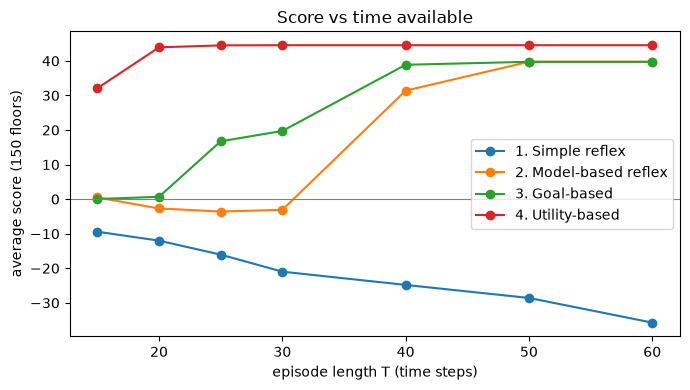

    1. Simple reflex  2. Model-based reflex  3. Goal-based  4. Utility-based
T                                                                           
15              -9.4                    0.5            0.0              32.1
20             -12.0                   -2.7            0.7              43.9
25             -16.1                   -3.6           16.7              44.5
30             -21.0                   -3.1           19.7              44.5
40             -24.8                   31.4           38.9              44.5
50             -28.6                   39.7           39.7              44.5
60             -35.7                   39.7           39.7              44.5


In [15]:
horizons = [15, 20, 25, 30, 40, 50, 60]
sweep = {name: [] for name in factories}
for T in horizons:
    for name, make_agent in factories.items():
        if name.startswith("4"):
            agent_maker = lambda: UtilityBasedAgent(P_DIRT, steps=T)   # utility agent must know T
        else:
            agent_maker = make_agent
        sweep[name].append(np.mean([run_episode(agent_maker(), d, steps=T)[0] for d in layouts[:150]]))

fig, ax = plt.subplots(figsize=(7, 4))
for name, vals in sweep.items():
    ax.plot(horizons, vals, marker="o", label=name)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("episode length T (time steps)"); ax.set_ylabel("average score (150 floors)")
ax.set_title("Score vs time available")
ax.legend(); plt.tight_layout(); plt.show()
print(pd.DataFrame(sweep, index=horizons).round(1).rename_axis("T").to_string())

**What just happened?** When time is **short** (T = 15 or 20), the goal-based agent spends its moves on the nearby, rarely dirty squares. The utility-based agent heads for the kitchen and scores far higher. When time is **long** (T ≥ 50), the model-based and goal-based agents both get round the whole floor and reach the same score. The utility agent still wins because it never pays for walks that are not worth it. A goal ("visit everything") cannot express this trade-off, but a utility can.

### 5.5 Learning agent

**Definition.** A **learning agent** can improve its performance with experience. AIMA splits it into 4 parts:

| Component | Job | In our robot |
|---|---|---|
| **Performance element** | chooses actions (any of the agents above) | the utility-based agent, using the *estimated* dirt probabilities |
| **Critic** | tells the agent how well it is doing, against a fixed performance standard | the observed dirt in each visited square, and the score |
| **Learning element** | improves the performance element using the critic's feedback | updates the estimate $\hat P(\text{dirty})$ for each square from counts |
| **Problem generator** | suggests *exploratory* actions that may be worse now but teach something new | on some episodes, sweep the whole floor (goal-based) to collect data |

Our learning robot does **not** know where the kitchen is. It starts with the same belief everywhere, $\hat P = 0.5$. After each episode it updates, for every square it observed, the counts of "dirty" and "clean" first visits:

$$\hat P(\text{dirty}_x) = \frac{\text{dirty}_x + 1}{\text{dirty}_x + \text{clean}_x + 2}$$

(this "+1, +2" is **Laplace smoothing**: it starts at 0.5 and never reaches exactly 0 or 1). The first 3 episodes, and about 10% of later ones, are exploratory sweeps.

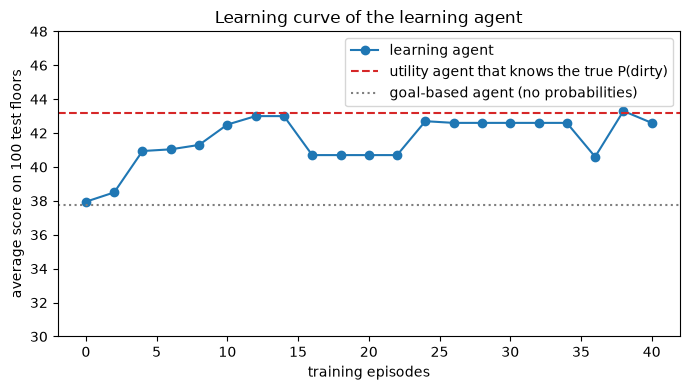

 episodes of experience  test score
                      0        38.0
                      2        38.5
                      4        40.9
                     10        42.5
                     40        42.6
reference (true probabilities): 43.2 | goal-based reference: 37.8

learned P(dirty) in the kitchen: {(4, 3): 0.74, (4, 4): 0.83, (4, 5): 0.81, (5, 3): 0.83, (5, 4): 0.88, (5, 5): 0.71}


In [16]:
def run_episode_observing(agent, dirt, steps=T_STEPS):
    # Like run_episode, but also records what the robot saw on each square's first visit.
    pos, dirt, score, bumped = START, set(dirt), 0, False
    first_seen = {pos: pos in dirt}                    # square -> was it dirty on first visit?
    for t in range(steps):
        action = agent((pos in dirt, bumped)); bumped = False
        if action == "Suck":
            if pos in dirt: dirt.discard(pos); score += 10
            else: score -= 1
        elif action in MOVES:
            score -= 1; pos, bumped = try_move(pos, action)
            first_seen.setdefault(pos, pos in dirt)    # record only the first observation
    return score, first_seen

class LearningVacuumAgent:
    def __init__(self, rng, explore_prob=0.1, n_warmup=3):
        self.dirty_count = {c: 0 for c in FREE}          # learning element's memory
        self.clean_count = {c: 0 for c in FREE}
        self.rng, self.explore_prob, self.n_warmup = rng, explore_prob, n_warmup
        self.episodes = 0

    def p_hat(self):
        # Laplace-smoothed estimate of P(dirty) for every square.
        return {c: (self.dirty_count[c] + 1) / (self.dirty_count[c] + self.clean_count[c] + 2) for c in FREE}

    def performance_element(self):
        return UtilityBasedAgent(self.p_hat())          # act on current beliefs

    def problem_generator(self):
        # Explore during warm-up, then occasionally.
        explore = self.episodes < self.n_warmup or self.rng.random() < self.explore_prob
        return GoalBasedAgent() if explore else None

    def live_one_episode(self, dirt):
        agent = self.problem_generator() or self.performance_element()
        score, seen = run_episode_observing(agent, dirt)
        for cell, was_dirty in seen.items():             # critic's feedback -> learning element
            if was_dirty: self.dirty_count[cell] += 1
            else: self.clean_count[cell] += 1
        self.episodes += 1
        return score

learner = LearningVacuumAgent(random.Random(7))
train_rng = random.Random(2024)
test_floors = layouts[:100]                              # fixed test floors for a smooth curve
curve = []
for episode in range(0, 41):
    if episode > 0:
        learner.live_one_episode(make_dirt(train_rng))   # one day of real experience
    if episode % 2 == 0:                                 # evaluate the greedy (non-exploring) policy
        p_now = learner.p_hat()
        test_score = np.mean([run_episode(UtilityBasedAgent(p_now), d)[0] for d in test_floors])
        curve.append((episode, test_score))
curve = pd.DataFrame(curve, columns=["episodes of experience", "test score"])
utility_ref = np.mean([run_episode(UtilityBasedAgent(P_DIRT), d)[0] for d in test_floors])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curve["episodes of experience"], curve["test score"], marker="o", label="learning agent")
ax.axhline(utility_ref, color="tab:red", ls="--", label="utility agent that knows the true P(dirty)")
goal_ref = np.mean([run_episode(GoalBasedAgent(), d)[0] for d in test_floors])
ax.axhline(goal_ref, color="tab:gray", ls=":", label="goal-based agent (no probabilities)")
ax.set_ylim(30, 48)
ax.set_xlabel("training episodes"); ax.set_ylabel("average score on 100 test floors")
ax.set_title("Learning curve of the learning agent"); ax.legend(); plt.tight_layout(); plt.show()
print(curve.iloc[[0, 1, 2, 5, -1]].round(1).to_string(index=False))
print("reference (true probabilities):", round(utility_ref, 1), "| goal-based reference:", round(goal_ref, 1))

learned = learner.p_hat()
print("\nlearned P(dirty) in the kitchen:", {c: round(learned[c], 2) for c in sorted(KITCHEN)})
assert all(abs(learned[c] - 0.8) < 0.15 for c in KITCHEN)          # kitchen found
assert curve["test score"].iloc[-1] > curve["test score"].iloc[0]  # it improved

**What just happened?**
- With **no experience** (episode 0), the robot believes every square is dirty with probability 0.5. It plans as if the whole floor were worth cleaning, and does about as well as the goal-based sweep.
- After a few exploratory sweeps, the **learning element** has discovered the kitchen: its estimates there are close to the true 0.8. The **performance element** (the utility agent) now heads for the kitchen, and the test score climbs close to the red line, the score of a robot that was *told* the true probabilities.
- The curve wobbles. After only a few episodes each square's estimate rests on a handful of observations, so one unlucky floor can shift it. More experience makes the estimates, and the score, more stable.
- We never wrote "the kitchen is bottom-right" in the learner's code. It **learned** that from experience. This is the bridge from classical AI to **machine learning** and **reinforcement learning**.

### Summary of agent types

| Agent type | Uses memory? | Looks ahead? | Trade-offs? | Learns? | Our average score (T = 40) |
|---|---|---|---|---|---|
| Simple reflex | no | no | no | no | −24.5 |
| Model-based reflex | yes (internal state) | no | no | no | 31.5 |
| Goal-based | yes | yes (search) | no (goal is yes/no) | no | 38.6 |
| Utility-based | yes | yes | yes (expected utility) | no | 44.6 |
| Learning | yes | yes | yes | **yes** | approaches the utility agent |

> 🎓 **Exam / interview tip:** a classic question is "why is a goal not enough?" Answer: goals only separate success from failure. A utility function can (1) choose between conflicting goals (speed vs safety), (2) weigh likelihood of success against importance when no goal is certain, and (3) prefer cheaper or quicker ways to reach the same goal.

**Complexity of one decision.** Simple reflex: $O(1)$. Model-based reflex: $O(1)$ (check 4 neighbours). Goal-based: one breadth-first search over the $n = 31$ free squares, $O(n)$, each time a new plan is needed. Utility-based: the same search plus a path for each candidate square, $O(n^2)$ per new plan.

## 6. Problem formulation

> 💬 **In plain English:** before a computer can search for a solution, we must write down the start, the possible moves, the goal and the cost.

The goal-based agent above solved its problem by **search**: it imagined sequences of moves before making them. To search, you first need to **formulate** the problem precisely. Formulation is half of the work: a good formulation keeps only the details that matter. Leaving out the rest is called **abstraction**.

A **search problem** is defined by the parts below (AIMA chapter 3). The five you must always write down are the **initial state**, **actions**, **transition model**, **goal test** and **path cost**. Together they define the **state space**.

| Part | Meaning | Route-finding example |
|---|---|---|
| **State space** | the set of all possible states | which city you are in |
| **Initial state** | where the agent starts | `Ashford` |
| **Actions** `ACTIONS(s)` | the actions applicable in state `s` | drive along any road leaving the current city |
| **Transition model** `RESULT(s, a)` | the state that results from doing `a` in `s` | `RESULT(Ashford, go to Brookvale) = Brookvale` |
| **Goal test** `IS-GOAL(s)` | is `s` a goal state? (there may be many goal states) | `s == Lakeside` |
| **Action cost** `ACTION-COST(s, a, s')` → **path cost** | the cost of one step; the path cost is the sum of step costs | road length in km |

- A **solution** is a sequence of actions from the initial state to a goal state.
- An **optimal solution** has the lowest path cost of all solutions.
- The states and actions form a **state-space graph**: nodes are states, edges are actions.

Here is a small, general `Problem` class that we will reuse. Each concrete problem fills in the methods.

In [17]:
class Problem:
    # A search problem: subclasses override actions, result, is_goal and (optionally) action_cost.
    def __init__(self, initial, goal=None):
        self.initial = initial                  # initial state
        self.goal = goal                        # goal state (if there is a single one)

    def actions(self, state):                   # ACTIONS(s)
        raise NotImplementedError

    def result(self, state, action):            # RESULT(s, a): the transition model
        raise NotImplementedError

    def is_goal(self, state):                   # IS-GOAL(s)
        return state == self.goal

    def action_cost(self, state, action, next_state):   # ACTION-COST(s, a, s')
        return 1                                # default: every step costs 1

    def path_cost(self, actions):
        # Apply a list of actions from the initial state; return (final state, total cost).
        state, cost = self.initial, 0
        for a in actions:
            assert a in self.actions(state), f"action {a} not allowed in {state}"
            nxt = self.result(state, a)
            cost += self.action_cost(state, a, nxt)
            state = nxt
        return state, cost

def reachable_states(problem):
    # Flood fill: every state reachable from the initial state (explained properly in notebook 02).
    seen, queue = {problem.initial}, deque([problem.initial])
    while queue:
        s = queue.popleft()
        for a in problem.actions(s):
            nxt = problem.result(s, a)
            if nxt not in seen:
                seen.add(nxt); queue.append(nxt)
    return seen

### State-space graph vs search tree

- The **state-space graph** has **one node per state**. It is a property of the problem.
- A **search tree** is what a search algorithm *builds* while exploring. The root is the initial state; each tree **node** stands for a **path** to a state. The same state can appear many times in the tree, once for every path that reaches it. These are **repeated states**. If the graph has a cycle, the tree is **infinite**.

*Analogy:* the state-space graph is the road map; the search tree is the list of every journey you could take on it, including ones that drive round in circles.

**By hand.** Take this graph with 4 states and a cycle `S-A-B-S`:

```
      S
     / \
    A---B        edges: S-A, S-B, A-B, A-G, B-G
     \ /
      G
```

Unrolling it from `S` to depth 2 gives:

```
depth 0:              S
depth 1:        A           B
depth 2:     S  B  G     S  A  G
```

That is 9 tree nodes but only 4 distinct states. `S` already appears 3 times, and the tree keeps growing as depth increases. The code draws both pictures and counts how fast the tree grows.

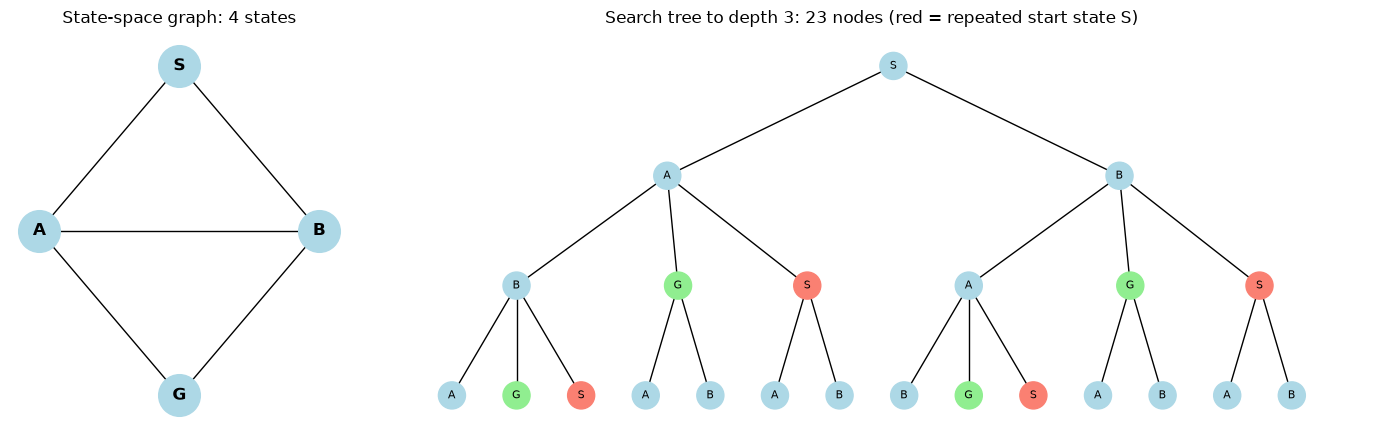

depth              0  1  2   3   4    5    6     7     8
search-tree nodes  1  3  9  23  61  155  401  1023  2629
distinct states in the graph: 4


In [18]:
small = nx.Graph([("S", "A"), ("S", "B"), ("A", "B"), ("A", "G"), ("B", "G")])

def unroll(graph, root, depth):
    # Build the search tree (no repeated-state checking) down to `depth`.
    tree = nx.DiGraph()
    tree.add_node(0, label=root, depth=0)
    frontier, next_id = [0], 1
    for d in range(1, depth + 1):
        new_frontier = []
        for node in frontier:
            for nbr in sorted(graph.neighbors(tree.nodes[node]["label"])):
                tree.add_node(next_id, label=nbr, depth=d)
                tree.add_edge(node, next_id)
                new_frontier.append(next_id); next_id += 1
        frontier = new_frontier
    return tree

def tree_layout(tree, root=0):
    # Simple top-down tree layout: leaves get x = 0, 1, 2, ...; parents sit above their children.
    pos, next_x = {}, [0]
    def place(node, depth):
        kids = list(tree.successors(node))
        if not kids:
            pos[node] = (next_x[0], -depth); next_x[0] += 1
        else:
            for k in kids:
                place(k, depth + 1)
            pos[node] = (np.mean([pos[k][0] for k in kids]), -depth)
    place(root, 0)
    return pos

tree = unroll(small, "S", depth=3)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 3]})
nx.draw(small, pos={"S": (0, 1), "A": (-1, 0), "B": (1, 0), "G": (0, -1)}, ax=axes[0], with_labels=True,
        node_color="lightblue", node_size=900, font_weight="bold")
axes[0].set_title("State-space graph: 4 states")
labels = nx.get_node_attributes(tree, "label")
colors = ["salmon" if labels[n] == "S" and n != 0 else "lightgreen" if labels[n] == "G" else "lightblue" for n in tree]
nx.draw(tree, pos=tree_layout(tree), ax=axes[1], labels=labels, node_color=colors, node_size=380,
        font_size=8, arrows=False)
axes[1].set_title(f"Search tree to depth 3: {tree.number_of_nodes()} nodes (red = repeated start state S)")
plt.tight_layout(); plt.show()

counts = [(d, unroll(small, "S", d).number_of_nodes()) for d in range(0, 9)]
print(pd.DataFrame(counts, columns=["depth", "search-tree nodes"]).T.to_string(header=False))
print("distinct states in the graph:", small.number_of_nodes())

**What just happened?** The graph never changes size (4 states), but the search tree grows **exponentially** with depth, because every cycle can be walked again and again. The red nodes are paths that came back to `S`.

This is why notebook 02 introduces **graph search**: it remembers which states have already been reached and does not expand them again. With it, the work is bounded by the number of *states* instead of the number of *paths*.

> ⚠️ **Common mistake:** confusing a **node** with a **state**. A state is a configuration of the world. A node is a data structure in the search tree. It holds a state, a parent pointer, the action that led to it and the path cost $g$. Two different nodes can hold the same state.

Grids show the same effect. In a 4-connected grid, the number of paths of length $d$ is $4^d$. The number of distinct squares within $d$ steps of the start (on an unbounded grid) is only $2d^2 + 2d + 1$. Let's check that formula by enumeration.

In [19]:
rows = []
for d in range(0, 9):
    paths = 4 ** d                                          # tree nodes at depth exactly d
    within = {(x, y) for x in range(-d, d + 1) for y in range(-d, d + 1) if abs(x) + abs(y) <= d}
    assert len(within) == 2 * d * d + 2 * d + 1             # check the closed form
    rows.append((d, paths, len(within)))
print(pd.DataFrame(rows, columns=["depth d", "paths of length d (4^d)", "distinct squares within d"]).to_string(index=False))

 depth d  paths of length d (4^d)  distinct squares within d
       0                        1                          1
       1                        4                          5
       2                       16                         13
       3                       64                         25
       4                      256                         41
       5                     1024                         61
       6                     4096                         85
       7                    16384                        113
       8                    65536                        145


**What just happened?** At depth 8 there are 65,536 different paths, but they visit only 145 distinct squares. The tree is exponential in $d$; the set of states is only quadratic. Graph search exploits exactly this gap.

## 7. Four example formulations

> 💬 **In plain English:** four classic puzzles, each written down in the same five-part recipe and drawn as a map of states.

### 7.1 The 8-puzzle

A 3 × 3 board with tiles 1-8 and one blank. You slide a tile into the blank. The goal is to reach the ordered layout.

| Part | Formulation |
|---|---|
| States | where each of the 8 tiles and the blank are: a tuple of 9 numbers read row by row, `0` = blank |
| Initial state | any layout, e.g. `(1, 2, 3, 4, 0, 5, 7, 8, 6)` |
| Actions | move the **blank** `Up`, `Down`, `Left` or `Right` (only those that stay on the board) |
| Transition model | swap the blank with the neighbouring tile |
| Goal test | state == `(1, 2, 3, 4, 5, 6, 7, 8, 0)` |
| Path cost | 1 per move |

There are $9! = 362{,}880$ ways to place the tiles, but exactly half of them, **181,440**, can be reached from any given layout. The other half can never be reached (notebook 03 explains why, with a parity argument). We check this number below.

In [20]:
class EightPuzzle(Problem):
    GOAL = (1, 2, 3, 4, 5, 6, 7, 8, 0)
    DELTAS = {"Up": -3, "Down": +3, "Left": -1, "Right": +1}   # index change of the blank

    def __init__(self, initial):
        super().__init__(initial, self.GOAL)

    def actions(self, state):
        i = state.index(0)                       # where the blank is
        row, col = divmod(i, 3)
        acts = []
        if row > 0: acts.append("Up")
        if row < 2: acts.append("Down")
        if col > 0: acts.append("Left")
        if col < 2: acts.append("Right")
        return acts

    def result(self, state, action):
        i = state.index(0)
        j = i + self.DELTAS[action]              # the tile that swaps with the blank
        s = list(state)
        s[i], s[j] = s[j], s[i]
        return tuple(s)

def show_board(state):
    return "\n".join(" ".join("." if v == 0 else str(v) for v in state[r * 3:(r + 1) * 3]) for r in range(3))

puzzle = EightPuzzle((1, 2, 3, 4, 0, 5, 7, 8, 6))
print(show_board(puzzle.initial))
print("actions:", puzzle.actions(puzzle.initial))
final, cost = puzzle.path_cost(["Right", "Down"])        # try a 2-move solution
print("after Right, Down:\n" + show_board(final), "\nis goal?", puzzle.is_goal(final), "| cost:", cost)

n_reachable = len(reachable_states(puzzle))
print("reachable states:", n_reachable, "| 9!/2 =", math.factorial(9) // 2)
assert n_reachable == math.factorial(9) // 2

1 2 3
4 . 5
7 8 6
actions: ['Up', 'Down', 'Left', 'Right']
after Right, Down:
1 2 3
4 5 6
7 8 . 
is goal? True | cost: 2


reachable states: 181440 | 9!/2 = 181440


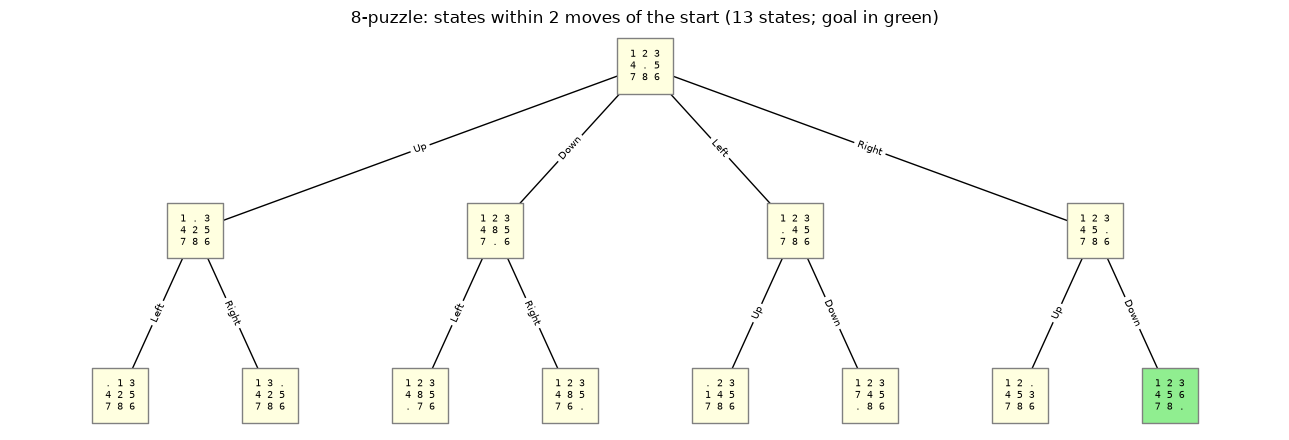

In [21]:
# Draw the first two levels of the search space around the initial state (each state once).
def bfs_tree(problem, depth):
    tree = nx.DiGraph(); tree.add_node(problem.initial)
    level, seen = [problem.initial], {problem.initial}
    for _ in range(depth):
        nxt_level = []
        for s in level:
            for a in problem.actions(s):
                child = problem.result(s, a)
                if child not in seen:
                    seen.add(child); tree.add_edge(s, child, action=a); nxt_level.append(child)
        level = nxt_level
    return tree

t8 = bfs_tree(puzzle, depth=2)
pos = tree_layout(t8, root=puzzle.initial)
fig, ax = plt.subplots(figsize=(13, 4.5))
node_colors = ["lightgreen" if s == EightPuzzle.GOAL else "lightyellow" for s in t8]
nx.draw(t8, pos, ax=ax, labels={s: show_board(s) for s in t8}, node_shape="s", node_size=1600,
        node_color=node_colors, edgecolors="gray", font_size=7, font_family="monospace", arrows=False)
nx.draw_networkx_edge_labels(t8, pos, edge_labels=nx.get_edge_attributes(t8, "action"), font_size=7, ax=ax)
ax.set_title(f"8-puzzle: states within 2 moves of the start ({t8.number_of_nodes()} states; goal in green)")
plt.tight_layout(); plt.show()

**What just happened?** With the blank in the centre there are 4 moves. Each child has 3 moves, but one of them undoes the previous move. That leaves 2 new states per child, giving 1 + 4 + 8 = 13 states. The goal (green) is 2 moves away: `Right`, then `Down`. The **branching factor** of the 8-puzzle is 2 with the blank in a corner, 3 on an edge and 4 in the centre: about 2.7 on average over the 9 blank positions, or "about 3" as textbooks usually round it.

### 7.2 Route finding on a small map

We define a made-up region with 12 towns. The numbers on the roads are lengths in km. Each road is at least as long as the straight line between its towns (roads bend). Notebook 03 relies on that fact.

| Part | Formulation |
|---|---|
| States | the town you are in |
| Initial state | `Ashford` |
| Actions | drive to a neighbouring town along a road |
| Transition model | `RESULT(city, go(X)) = X` |
| Goal test | city == `Lakeside` |
| Path cost | sum of road lengths (km) |

ACTIONS(Ashford) = ['Brookvale', 'Cedar Falls']
cost of Ashford -> Cedar Falls -> Elmstead -> Glenwood -> Kingsport -> Lakeside: 141 km


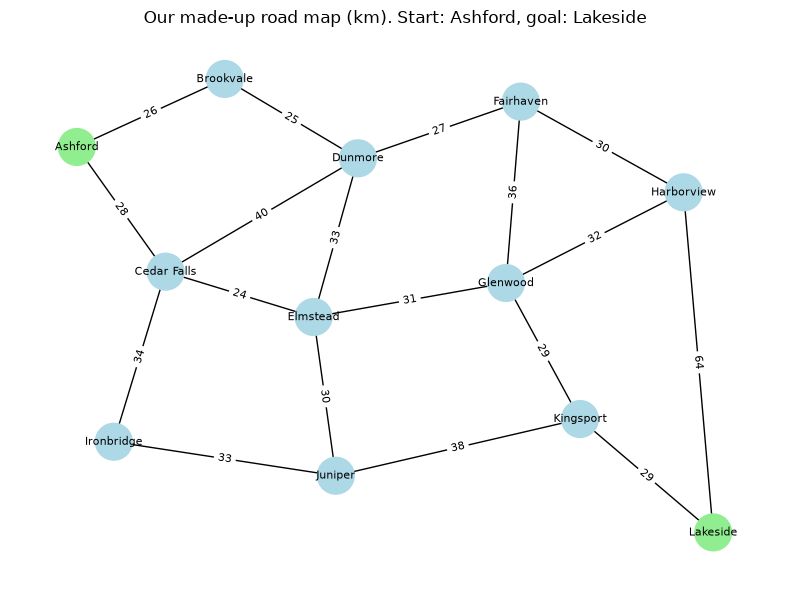

In [22]:
CITY_XY = {  # town -> (x, y) position in km on our made-up map
    "Ashford": (10, 80), "Brookvale": (30, 92), "Cedar Falls": (22, 58), "Dunmore": (48, 78),
    "Elmstead": (42, 50), "Fairhaven": (70, 88), "Glenwood": (68, 56), "Harborview": (92, 72),
    "Ironbridge": (15, 28), "Juniper": (45, 22), "Kingsport": (78, 32), "Lakeside": (96, 12),
}
ROADS = [  # (town, town, road length in km)
    ("Ashford", "Brookvale", 26), ("Ashford", "Cedar Falls", 28), ("Brookvale", "Dunmore", 25),
    ("Cedar Falls", "Dunmore", 40), ("Cedar Falls", "Elmstead", 24), ("Cedar Falls", "Ironbridge", 34),
    ("Dunmore", "Fairhaven", 27), ("Dunmore", "Elmstead", 33), ("Elmstead", "Glenwood", 31),
    ("Elmstead", "Juniper", 30), ("Fairhaven", "Harborview", 30), ("Fairhaven", "Glenwood", 36),
    ("Glenwood", "Harborview", 32), ("Glenwood", "Kingsport", 29), ("Ironbridge", "Juniper", 33),
    ("Juniper", "Kingsport", 38), ("Kingsport", "Lakeside", 29), ("Harborview", "Lakeside", 64),
]
road_map = {city: {} for city in CITY_XY}          # adjacency dict: city -> {neighbour: km}
for a, b, km in ROADS:
    road_map[a][b] = km; road_map[b][a] = km       # roads are two-way
    assert km >= math.dist(CITY_XY[a], CITY_XY[b]) # a road is never shorter than the straight line

class RouteProblem(Problem):
    def __init__(self, initial, goal, graph):
        super().__init__(initial, goal); self.graph = graph
    def actions(self, city):
        return sorted(self.graph[city])            # "go to X" for each neighbour X
    def result(self, city, action):
        return action
    def action_cost(self, city, action, next_city):
        return self.graph[city][next_city]

route = RouteProblem("Ashford", "Lakeside", road_map)
print("ACTIONS(Ashford) =", route.actions("Ashford"))
print("cost of Ashford -> Cedar Falls -> Elmstead -> Glenwood -> Kingsport -> Lakeside:",
      route.path_cost(["Cedar Falls", "Elmstead", "Glenwood", "Kingsport", "Lakeside"])[1], "km")

G_map = nx.Graph(); G_map.add_weighted_edges_from(ROADS)
fig, ax = plt.subplots(figsize=(8, 6))
nx.draw(G_map, CITY_XY, ax=ax, with_labels=True, node_color=["lightgreen" if c in ("Ashford", "Lakeside") else "lightblue" for c in G_map],
        node_size=700, font_size=8)
nx.draw_networkx_edge_labels(G_map, CITY_XY, edge_labels=nx.get_edge_attributes(G_map, "weight"), font_size=8, ax=ax)
ax.set_title("Our made-up road map (km). Start: Ashford, goal: Lakeside")
plt.tight_layout(); plt.show()

**What just happened?** The map is stored as a dictionary of dictionaries, the usual way to store a weighted graph (an **adjacency list**). `path_cost` checks every action is legal and adds up the km. The route via Glenwood and Kingsport costs 141 km. Is that the best? Notebook 02 finds out with uniform-cost search.

### 7.3 Missionaries and cannibals

Three missionaries and three cannibals must cross a river using a boat that holds at most 2 people. The boat cannot cross empty. If cannibals ever outnumber missionaries on either bank (when that bank has at least one missionary), the missionaries are eaten.

| Part | Formulation |
|---|---|
| States | `(m, c, b)`: missionaries and cannibals on the **left** bank, and `b = 1` if the boat is on the left |
| Initial state | `(3, 3, 1)` |
| Actions | the boat carries `(dm, dc)` people: `(1,0)`, `(2,0)`, `(0,1)`, `(0,2)` or `(1,1)` |
| Transition model | subtract the people from the boat's bank, add them to the other bank, flip `b`. Only **safe** results are allowed |
| Goal test | state == `(0, 0, 0)` |
| Path cost | 1 per crossing |

The abstraction is good: we ignore the river's width, the weather and who rows. Only the counts matter.

In [23]:
class MissionariesCannibals(Problem):
    LOADS = [(1, 0), (2, 0), (0, 1), (0, 2), (1, 1)]     # possible boat loads (missionaries, cannibals)

    def __init__(self, n=3, capacity=2):
        super().__init__((n, n, 1), (0, 0, 0)); self.n = n
        self.loads = [(dm, dc) for dm in range(capacity + 1) for dc in range(capacity + 1)
                      if 1 <= dm + dc <= capacity]

    def safe(self, m, c):
        # Both banks safe: missionaries absent or not outnumbered.
        n = self.n
        return 0 <= m <= n and 0 <= c <= n and (m == 0 or m >= c) and (n - m == 0 or n - m >= n - c)

    def actions(self, state):
        m, c, b = state
        sign = -1 if b == 1 else +1                       # boat on the left takes people away from the left
        return [(dm, dc) for dm, dc in self.loads if self.safe(m + sign * dm, c + sign * dc)]

    def result(self, state, action):
        m, c, b = state; dm, dc = action
        sign = -1 if b == 1 else +1
        return (m + sign * dm, c + sign * dc, 1 - b)

mc = MissionariesCannibals()
mc_states = reachable_states(mc)
print("reachable safe states:", len(mc_states))
print("ACTIONS((3,3,1)) =", mc.actions((3, 3, 1)))

# Build the state-space graph and (only for drawing) find the shortest route with networkx.
mc_graph = nx.Graph()
for s in mc_states:
    for a in mc.actions(s):
        mc_graph.add_edge(s, mc.result(s, a))
mc_path = nx.shortest_path(mc_graph, mc.initial, mc.goal)   # we write our own search in notebook 02
print("fewest crossings:", len(mc_path) - 1)
print(" -> ".join(str(s) for s in mc_path))
assert len(mc_path) - 1 == 11

reachable safe states: 16
ACTIONS((3,3,1)) = [(0, 1), (0, 2), (1, 1)]
fewest crossings: 11
(3, 3, 1) -> (3, 1, 0) -> (3, 2, 1) -> (3, 0, 0) -> (3, 1, 1) -> (1, 1, 0) -> (2, 2, 1) -> (0, 2, 0) -> (0, 3, 1) -> (0, 1, 0) -> (0, 2, 1) -> (0, 0, 0)


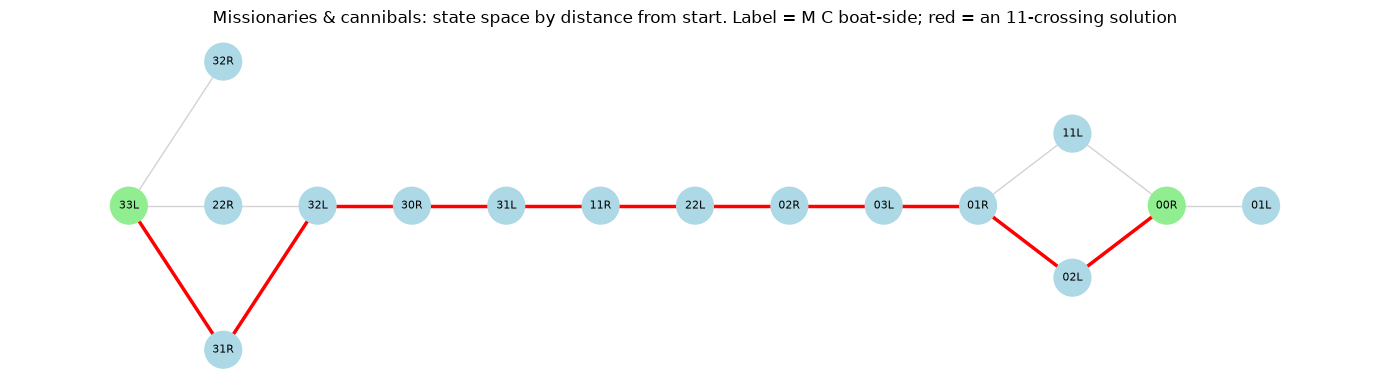

In [24]:
depth = nx.single_source_shortest_path_length(mc_graph, mc.initial)   # distance from the start
for s in mc_graph: mc_graph.nodes[s]["layer"] = depth[s]
pos = nx.multipartite_layout(mc_graph, subset_key="layer")
path_edges = set(zip(mc_path, mc_path[1:])) | set(zip(mc_path[1:], mc_path))
fig, ax = plt.subplots(figsize=(14, 4))
nx.draw(mc_graph, pos, ax=ax, labels={s: f"{s[0]}{s[1]}{'L' if s[2] else 'R'}" for s in mc_graph},
        node_color=["lightgreen" if s in (mc.initial, mc.goal) else "lightblue" for s in mc_graph],
        edge_color=["red" if e in path_edges else "lightgray" for e in mc_graph.edges()],
        width=[2.5 if e in path_edges else 1 for e in mc_graph.edges()], node_size=700, font_size=8)
ax.set_title("Missionaries & cannibals: state space by distance from start. Label = M C boat-side; red = an 11-crossing solution")
plt.tight_layout(); plt.show()

**What just happened?** Of the 32 combinations of `(m, c, b)`, only 16 are safe *and* reachable. The state space is a long, narrow corridor with a few dead ends, and the shortest solution needs **11 crossings**. The picture puts each state in a column by its distance from the start. The left-most column is `33L` (everyone on the left). The goal `00R` (everyone across) is green, near the right. `01L` lies beyond it because a cannibal could row back after the goal is reached, but a search stops at the goal.

### 7.4 The water jug problem

You have a 4-litre jug and a 3-litre jug, no markings, and a tap. Get **exactly 2 litres in the 4-litre jug**.

| Part | Formulation |
|---|---|
| States | `(x, y)`: litres in the 4-L jug and in the 3-L jug, `0 ≤ x ≤ 4`, `0 ≤ y ≤ 3` |
| Initial state | `(0, 0)` |
| Actions | fill a jug, empty a jug, pour one jug into the other until the source is empty or the target is full |
| Transition model | e.g. `RESULT((4, 0), pour 4→3) = (1, 3)` |
| Goal test | `x == 2` (any `y`: many goal states) |
| Path cost | 1 per action |

The state space is **directed**: you can fill a jug in one action, but you cannot always un-fill it to the previous level.

reachable states: 14 of 20 combinations
goal states: [(2, 0), (2, 3)] | fewest actions: 6 | path: [(0, 0), (0, 3), (3, 0), (3, 3), (4, 2), (0, 2), (2, 0)]


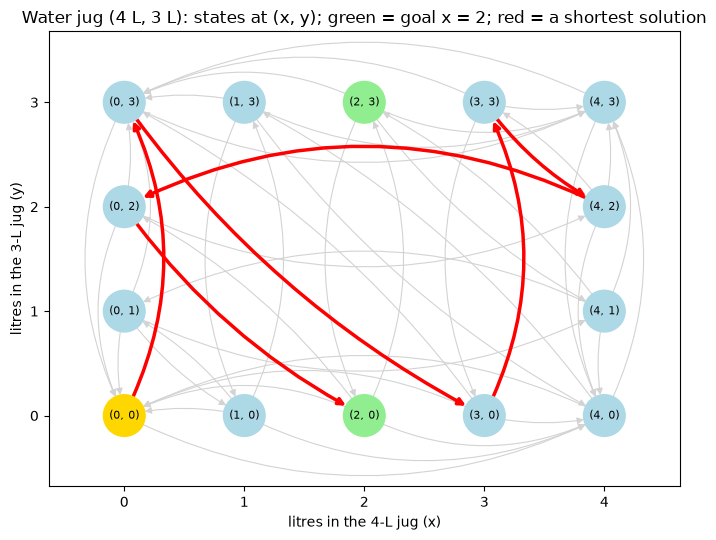

In [25]:
class WaterJug(Problem):
    def __init__(self, capacities=(4, 3), target=2):
        super().__init__((0, 0)); self.cap, self.target = capacities, target

    def _apply(self, state, action):
        x, y = state; A, B = self.cap
        if action == "fill A":  return (A, y)
        if action == "fill B":  return (x, B)
        if action == "empty A": return (0, y)
        if action == "empty B": return (x, 0)
        if action == "pour A->B":
            t = min(x, B - y); return (x - t, y + t)     # pour until A is empty or B is full
        if action == "pour B->A":
            t = min(y, A - x); return (x + t, y - t)

    def actions(self, state):
        names = ["fill A", "fill B", "empty A", "empty B", "pour A->B", "pour B->A"]
        return [a for a in names if self._apply(state, a) != state]   # skip actions that change nothing

    def result(self, state, action):
        return self._apply(state, action)

    def is_goal(self, state):
        return state[0] == self.target

jug = WaterJug()
jug_states = reachable_states(jug)
print("reachable states:", len(jug_states), "of", 5 * 4, "combinations")
jug_graph = nx.DiGraph()
for s in jug_states:
    for a in jug.actions(s):
        jug_graph.add_edge(s, jug.result(s, a), action=a)

goals = [s for s in jug_states if jug.is_goal(s)]
best = min((nx.shortest_path(jug_graph, jug.initial, g) for g in goals), key=len)   # for drawing only
print("goal states:", sorted(goals), "| fewest actions:", len(best) - 1, "| path:", best)
assert len(best) - 1 == 6

fig, ax = plt.subplots(figsize=(7, 5.5))
pos = {s: (s[0], s[1]) for s in jug_graph}
best_edges = set(zip(best, best[1:]))
nx.draw_networkx_nodes(jug_graph, pos, ax=ax, node_size=900,
        node_color=["lightgreen" if jug.is_goal(s) else "gold" if s == jug.initial else "lightblue" for s in jug_graph])
nx.draw_networkx_labels(jug_graph, pos, ax=ax, font_size=8)
for edges, color, width in [([e for e in jug_graph.edges() if e not in best_edges], "lightgray", 0.8),
                            (list(best_edges), "red", 2.5)]:
    # long edges along a row or column would pass through other nodes, so bend them more
    long_ = [(u, v) for u, v in edges if (u[0] == v[0] or u[1] == v[1]) and math.dist(u, v) > 1]
    short = [e for e in edges if e not in long_]
    for group, rad in [(short, 0.12), (long_, 0.25)]:
        nx.draw_networkx_edges(jug_graph, pos, edgelist=group, ax=ax, edge_color=color, width=width,
                               connectionstyle=f"arc3,rad={rad}", arrowsize=10, node_size=900)
ax.set_title("Water jug (4 L, 3 L): states at (x, y); green = goal x = 2; red = a shortest solution")
ax.set_axis_on(); ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
ax.set_xticks(range(5)); ax.set_yticks(range(4))
ax.set_xlabel("litres in the 4-L jug (x)"); ax.set_ylabel("litres in the 3-L jug (y)")
plt.tight_layout(); plt.show()

**What just happened?** Only 14 of the 20 `(x, y)` combinations are reachable. After any action, at least one jug is empty or full, so states like `(2, 2)` can never occur. The shortest solution takes **6 actions**: fill the 3-L jug, pour it into the 4-L jug, fill the 3-L jug again, pour until the 4-L jug is full (leaving 2 L in the 3-L jug), empty the 4-L jug, and pour the 2 L across.

### Summary of the four formulations

| Problem | State | # reachable states | Branching factor | Step cost | Graph type |
|---|---|---|---|---|---|
| 8-puzzle | tuple of 9 tiles | 181,440 | 2-4 | 1 | undirected (every move can be undone) |
| Route finding | city | 12 | 2-4 roads per town | road km (varies) | undirected, weighted |
| Missionaries & cannibals | `(m, c, b)` | 16 | ≤ 5 | 1 | undirected |
| Water jug | `(x, y)` | 14 | ≤ 6 | 1 | **directed** |

> 🎓 **Exam / interview tip:** when asked to "formulate" a problem, always give all 5 parts *and* say how big the state space is. Examiners also like the **8-queens** problem, which has two formulations: **incremental** (add one queen at a time to an empty board) and **complete-state** (all 8 queens on the board; move one at a time). Practice problem 4 below covers it.

## 8. A map of the rest of this track

> 💬 **In plain English:** where each of the next notebooks goes, and which idea from this one it builds on.

Every notebook in this folder builds on the agent and problem ideas from this one. The last column says which idea from this notebook each one takes further.

| # | Notebook | What you will do | Builds on |
|---|---|---|---|
| 02 | [Uninformed search](02_uninformed_search.ipynb) | BFS, DFS, depth-limited, iterative deepening, uniform-cost and bidirectional search on a maze and the road map | goal-based agents in known, deterministic, fully observable, discrete worlds (Sections 5.3 and 6) |
| 03 | [Informed (heuristic) search](03_informed_search.ipynb) | heuristics, greedy best-first, A*, IDA*, weighted A*; the 8-puzzle with two heuristics | the same agents, now using problem knowledge to search far less |
| 04 | [Local search and optimization](04_local_search_and_optimization.ipynb) | hill climbing, simulated annealing, local beam search, genetic algorithms on N-Queens and a travelling-salesperson tour | problems where only the final state matters, not the path (a utility to maximise) |
| 05 | [Adversarial search and games](05_adversarial_search_and_games.ipynb) | minimax, alpha-beta pruning, evaluation functions, expectimax, Monte Carlo tree search | multi-agent, competitive environments |
| 06 | [Constraint satisfaction problems](06_constraint_satisfaction.ipynb) | variables, domains and constraints; backtracking search and constraint propagation | factored states: a state is a set of variables with values |
| 07 | [Knowledge representation and logic](07_knowledge_representation_and_logic.ipynb) | knowledge bases, propositional and first-order logic, inference (resolution, chaining, DPLL), the Wumpus world | knowledge-based agents in partially observable worlds |
| 08 | [Reasoning and planning](08_reasoning_and_planning.ipynb) | types of reasoning; classical planning with STRIPS/PDDL, forward and backward planners, blocks world | goal-based agents whose states and actions are described in logic |
| 09 | [Uncertain knowledge and reasoning](09_uncertain_knowledge_and_reasoning.ipynb) | probability, Bayes' rule, Bayesian networks, hidden Markov models, decisions under uncertainty | stochastic, partially observable environments; utility-based agents |
| 10 | [Fuzzy logic and expert systems](10_fuzzy_logic_and_expert_systems.ipynb) | fuzzy sets and Mamdani inference; a rule-based expert system with forward and backward chaining | the symbolic AI of the 1980s expert-system boom (Section 1) |
| 11 | [Industry project: route planning and scheduling](11_industry_route_planning_and_scheduling.ipynb) | search and constraint satisfaction applied together to a realistic route-planning and driver-scheduling problem | everything above, in one end-to-end project |

After this track, continue with the main path: [`03_Machine_Learning/00_start_here_your_first_ml_model.ipynb`](../../03_Machine_Learning/00_start_here_your_first_ml_model.ipynb).

## 9. 🔗 How this connects to modern AI

> 💬 **In plain English:** the agent ideas in this notebook are exactly how today's LLM agents, robots and RL systems are designed.

- **LLM agents are agents in exactly this sense.** An LLM agent perceives (user messages, tool outputs), keeps internal state (conversation memory), and acts (calls tools, writes answers). Writing down its PEAS, especially the performance measure, is the first step of good agent design. See [`10_Agents/01_agent_fundamentals.ipynb`](../../10_Agents/01_agent_fundamentals.ipynb) and [`10_Agents/02_memory_and_planning.ipynb`](../../10_Agents/02_memory_and_planning.ipynb).
- **Reinforcement learning is the learning agent at scale.** Our learning robot estimated dirt probabilities from experience. RL agents learn values and policies the same way, with a reward signal playing the critic. See [`11_Reinforcement_Learning/01_rl_fundamentals.ipynb`](../../11_Reinforcement_Learning/01_rl_fundamentals.ipynb).
- **Utility-based thinking is everywhere in ML.** Loss functions, reward models and expected-value decisions are utility functions. Choosing the *right* performance measure is the same design problem as in Section 4.2, and getting it wrong is called **reward hacking** or **specification gaming**.
- **Problem formulation is still the hard part.** Robots, games and sat-navs formulate states, actions and costs, then search. Modern systems often *learn* parts of the formulation (a learned heuristic or a learned world model) and keep the search. AlphaGo and today's "reasoning" LLMs both combine learning with search: see [`08_LLM/18_reasoning_models.ipynb`](../../08_LLM/18_reasoning_models.ipynb).
- **Next step in the main path:** machine learning, where the knowledge comes from data: [`03_Machine_Learning/00_start_here_your_first_ml_model.ipynb`](../../03_Machine_Learning/00_start_here_your_first_ml_model.ipynb).

## 10. Recap

> 💬 **In plain English:** the key ideas of this notebook in a few bullets, then practice.

- **Symbolic (classical) AI** writes knowledge as symbols and rules and reaches goals by **search, logic and planning**. **Machine learning** learns from data. Modern headline systems are often hybrids.
- There were two **AI winters** (about 1974-1980 and 1987-1993), caused by over-promising.
- **By capability:** all AI that exists today is **narrow AI (ANI)**. **AGI** and **ASI** are hypothetical and have not been demonstrated.
- **By functionality:** reactive machines and limited-memory systems exist; theory-of-mind and self-aware AI do not.
- An **agent** maps percept sequences to actions (the **agent function**), implemented by an **agent program**. A **rational** agent maximises the *expected* performance measure given its percepts and knowledge. Rational is not omniscient.
- Describe a task with **PEAS** and classify its environment on 7 axes: observable, agents, deterministic, episodic, static, discrete, known.
- **Agent types:** simple reflex < model-based reflex < goal-based < utility-based, plus **learning** agents that improve any of them. In our vacuum world each step up raised the average score.
- A **search problem** = initial state + actions + transition model + goal test + path cost. The **state-space graph** has one node per state. A **search tree** has one node per path and can be infinite.

## Practice problems

**1. (Easy, conceptual)** Write a PEAS description for a drone that delivers parcels in a city.

<details><summary>Show solution</summary>

- **Performance:** parcels delivered on time and undamaged, safety (no collisions, no flying over restricted areas), low battery use, legal compliance, customer satisfaction.
- **Environment:** city airspace, buildings, trees, power lines, weather (wind, rain), other drones and aircraft, people, delivery locations, charging stations.
- **Actuators:** rotors (thrust, pitch, roll, yaw), gripper/winch to release the parcel, lights/speaker, radio to report status.
- **Sensors:** GPS, cameras, lidar/ultrasonic distance sensors, IMU (accelerometer, gyroscope), barometer, battery monitor, wind sensor, radio for instructions.

</details>

**2. (Easy, conceptual)** Classify **Sudoku** and **a robot playing football** on the 7 environment properties.

<details><summary>Show solution</summary>

| | Observable | Agents | Deterministic | Episodic | Static | Discrete | Known |
|---|---|---|---|---|---|---|---|
| Sudoku | fully | single | deterministic | sequential | static | discrete | known |
| Robot football | partially | multi (team-mates cooperate, opponents compete) | stochastic | sequential | dynamic | continuous | mostly known (physics), but opponents' strategies are unknown |

</details>

**3. (Medium, conceptual)** Is the simple reflex agent from Section 4.1 rational if (a) the performance measure gives +1 per clean square per step, (b) it also charges 1 point per move, (c) dirt can reappear at random?

<details><summary>Show solution</summary>

(a) **Yes** (AIMA's argument): no other agent can get a higher expected score, because it cleans whenever it can and moving is free. (b) **No**: once both squares are clean it keeps paying for moves. An agent with memory that stops (our model-based agent) does better, as the table in Section 4.2 showed. (c) Now moving is useful again, because a square may become dirty. Whether to move depends on how often dirt appears compared with the move cost. A good agent would check each square from time to time and wait in between. This answer is about *the measure and the environment*, not the agent alone.

</details>

**4. (Medium, coding)** Formulate the **8-queens** problem incrementally. (a) How many sequences are there if you may put each queen on any empty square? (b) How many states are there if you put one queen per column, left to right, only on squares not attacked by earlier queens? Write code to count them.

<details><summary>Show solution</summary>

```python
import math
# Incremental formulation, naive: place queens one by one in any empty square.
naive = math.perm(64, 8)                 # 64 * 63 * ... * 57 ordered placements
print(f"naive incremental sequences: {naive:.2e}")   # about 1.8e14
# Better: one queen per column, left to right, only in squares not attacked.
def count_states(n=8):
    count = 0
    def place(cols):                     # cols[i] = row of the queen in column i
        nonlocal count
        count += 1                       # every partial placement is a state
        if len(cols) == n:
            return
        c = len(cols)
        for r in range(n):
            if all(r != rr and abs(r - rr) != c - cc for cc, rr in enumerate(cols)):
                place(cols + [r])
    place([])
    return count
print("states with the improved formulation:", count_states())
assert count_states() == 2057
```

(a) $64 \times 63 \times \dots \times 57 \approx 1.8 \times 10^{14}$. (b) **2,057** states (AIMA's figure), counting the empty board and every partial placement. A good formulation shrinks the state space by a factor of about $10^{11}$.

</details>

**5. (Medium, coding)** Write `count_reachable_water_jug(a, b)` that returns the number of states reachable from `(0, 0)` for jugs of capacities `a` and `b`. Check that it gives 14 for `(4, 3)`.

<details><summary>Show solution</summary>

```python
from collections import deque

def count_reachable_water_jug(a, b):
    """Number of (x, y) states reachable from (0, 0) with jugs of capacity a and b."""
    def moves(x, y):
        yield a, y; yield x, b; yield 0, y; yield x, 0      # fill A, fill B, empty A, empty B
        t = min(x, b - y); yield x - t, y + t              # pour A -> B
        t = min(y, a - x); yield x + t, y - t              # pour B -> A
    seen, queue = {(0, 0)}, deque([(0, 0)])
    while queue:
        s = queue.popleft()
        for nxt in moves(*s):
            if nxt not in seen:
                seen.add(nxt); queue.append(nxt)
    return len(seen)

print(count_reachable_water_jug(4, 3))   # 14
print(count_reachable_water_jug(5, 3))   # 16
assert count_reachable_water_jug(4, 3) == 14
```

</details>

**6. (Medium, coding)** Write `table_size(n_percepts, lifetime)` for a table-driven agent, and prove (by testing several values) that it equals the closed form $p\,(p^T - 1)/(p - 1)$.

<details><summary>Show solution</summary>

```python
def table_size(n_percepts, lifetime):
    """Entries in a table-driven agent: one per percept sequence of length 1..lifetime."""
    return sum(n_percepts ** t for t in range(1, lifetime + 1))

def table_size_closed_form(p, T):
    # geometric series p + p^2 + ... + p^T = p (p^T - 1) / (p - 1), for p > 1
    return p * (p ** T - 1) // (p - 1)

for p in (2, 4, 10):
    for T in (1, 5, 10):
        assert table_size(p, T) == table_size_closed_form(p, T)
print(table_size(4, 10))   # 1398100
```

</details>

**7. (Hard, coding)** Generalise missionaries & cannibals to `n` of each and a boat of capacity `k`. Find the fewest crossings for `(n, k) = (3, 2)`, `(4, 2)` and `(4, 3)`.

<details><summary>Show solution</summary>

```python
from collections import deque

def solve_mc(n, capacity):
    """Fewest crossings for n missionaries + n cannibals, boat capacity `capacity` (None if impossible)."""
    loads = [(dm, dc) for dm in range(capacity + 1) for dc in range(capacity + 1) if 1 <= dm + dc <= capacity]
    def safe(m, c):
        return 0 <= m <= n and 0 <= c <= n and (m == 0 or m >= c) and (n - m == 0 or n - m >= n - c)
    start, goal = (n, n, 1), (0, 0, 0)
    dist, queue = {start: 0}, deque([start])
    while queue:
        m, c, b = s = queue.popleft()
        if s == goal:
            return dist[s]
        sign = -1 if b == 1 else 1
        for dm, dc in loads:
            nxt = (m + sign * dm, c + sign * dc, 1 - b)
            if safe(nxt[0], nxt[1]) and nxt not in dist:
                dist[nxt] = dist[s] + 1; queue.append(nxt)
    return None

print(solve_mc(3, 2))   # 11
print(solve_mc(4, 2))   # None: impossible
print(solve_mc(4, 3))   # 9
assert solve_mc(3, 2) == 11 and solve_mc(4, 2) is None and solve_mc(4, 3) == 9
```

With 4 of each and a 2-person boat the puzzle is **impossible**. A 3-person boat makes it solvable in 9 crossings.

</details>

**8. (Hard, conceptual)** Explain why the utility-based vacuum agent sometimes chooses `NoOp` while dirt is still on the floor, and why that is rational.

<details><summary>Show solution</summary>

Its utility is the *expected* score. An unvisited square outside the kitchen is dirty with probability 0.1, so visiting it is worth $10 \times 0.1 = 1$ point on average. Reaching it costs at least 1 move (−1). When every remaining plan has expected gain ≤ 0, doing nothing maximises expected performance. That is the definition of rational. On a particular floor it may miss some dirt (it is not omniscient), but averaged over floors it scores highest.

</details>

## Further reading

- Russell & Norvig, *Artificial Intelligence: A Modern Approach* (4th ed., 2020): Chapter 1 (history), Chapter 2 (intelligent agents), Section 3.1-3.2 (problem formulation).
- Nils J. Nilsson, *The Quest for Artificial Intelligence* (2010): a detailed history by one of the inventors of A\*. A free PDF is on the author's Stanford page.
- The AIMA code repository with Python implementations: <https://github.com/aimacode/aima-python>.

## Next notebook

➡️ [`02_uninformed_search.ipynb`](02_uninformed_search.ipynb): breadth-first, depth-first, iterative deepening, uniform-cost and bidirectional search, written from scratch and raced on a maze and on our road map.